[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T02_D_occbin_zlb_regimes_es.ipynb)

# Tema 2.D: Restricciones ocasionalmente activas: ZLB, inversión irreversible e incertidumbre

### Macroeconomía Avanzada (MAV) — Maestría en Economía, ITAM
**Profesor**: Jorge Alonso Ortiz

> **Nota para Google Colab**: la celda siguiente instala `puremacro` y, si hace falta, descarga del repositorio público [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro) sólo la carpeta `curso/notebooks` de la edición `course-2026A-5.5.0` (auxiliares, datos congelados y modelos). No pide acceso a Google Drive.

> **Actualización del 22 de octubre de 2026**: las secciones 8–9 incorporan inversión irreversible y volatilidad estocástica. Este cuaderno actualizado usa puremacro 5.5.0 y los auxiliares de la edición congelada; el tag original conserva su versión anterior. Ejecución comprobada en Python local; Colab no se ha vuelto a validar.

In [1]:
# Configuración: Google Colab, Python local o Juno (iPad)
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ['puremacro==5.5.0']
_course_edition = 'course-2026A-5.5.0'

def _safe_probe(p, is_dir=None):
    """Test paths without raising in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_course_requirements], check=True)
    # A separate directory per edition prevents reuse of helpers from another course.
    _repo = Path("/content/puremacro-" + _course_edition)
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", _course_edition, "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
    subprocess.run(["git", "-C", str(_repo), "checkout", "--detach", _course_edition], check=True)
    subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "curso/notebooks"], check=True)
    _course_status = subprocess.run(["git", "-C", str(_repo), "status", "--porcelain",
                                     "--untracked-files=normal", "--", "curso/notebooks"],
                                    check=True, capture_output=True, text=True).stdout
    if _course_status.strip():
        raise RuntimeError("The cached course edition was modified; use a fresh Colab runtime for the frozen edition.")
    os.chdir(_repo / "curso/notebooks")

# Locate the course helpers for local Python, Colab and Juno.
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

import puremacro
if puremacro.__version__ != "5.5.0":
    raise RuntimeError("This course edition requires puremacro==5.5.0; install it and restart the kernel.")

# Cached reference responses are the reproducible default; live models are optional.
os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Motivación Teórica: Por Qué Falla la Perturbación Lineal ante Fronteras Físicas

En la macroeconomía cuantitativa moderna, los modelos dinámicos estocásticos de equilibrio general (DSGE) se resuelven tradicionalmente mediante expansiones de Taylor de primer orden alrededor del estado estacionario determinista (Klein 2000, Schmitt-Grohé & Uribe 2004). La perturbación lineal asume que las funciones de política son planos diferenciables en todo el espacio de estados.

No obstante, las economías reales están sujetas a **no-linealidades fundamentales y límites físicos**:
1. **El Límite Inferior Cero (Zero Lower Bound / ELB)**: La tasa de interés nominal sobre las reservas del banco central no puede descender significativamente por debajo de cero debido al arbitraje con la tenencia de efectivo:
   $$i_t \ge 0 \quad \iff \quad \hat{r}_t \ge -r_{ss}$$
2. **Restricciones de Endeudamiento y Garantías (Sudden Stops)**: El endeudamiento externo de economías emergentes no puede exceder una fracción del colateral físico: $d_{t+1} \le \kappa q_t k_t$ (Mendoza 2010).
3. **Rigidez Nominal de Salarios a la Baja (DNWR)**: Los trabajadores resisten recortes nominales en su compensación salarial: $\Delta W_t \ge 0$ (Schmitt-Grohé & Uribe 2016).

Cuando una economía experimenta una contracción severa de demanda agregada (como en la Gran Recesión de 2008 o la pandemia de COVID-19 en 2020), la perturbación lineal prescribe que el banco central reduzca la tasa nominal a niveles profundamente negativos (en la Sección 1 de este cuaderno, $-8.8\%$ anualizado). Al ser esto imposible en la práctica, la tasa de interés real:
$$r_{t}^{\text{real}} = i_t - \mathbb{E}_t \pi_{t+1}$$
se ve impulsada **al alza** por la deflación esperada, desencadenando una **espiral deflacionaria** que amplifica el colapso del producto.

### La Solución Lineal por Partes: Guerrieri & Iacoviello (2015, JME)
Para resolver modelos con restricciones ocasionalmente activas sin incurrir en la prohibitiva maldición de la dimensionalidad de la iteración de función de valor (VFI), Guerrieri & Iacoviello (2015) desarrollaron el algoritmo **OccBin**:
- **Régimen de Referencia ($M_1$)**: La economía no restringida regida por una regla de Taylor activa.
- **Régimen Restringido ($M_2$)**: La economía bajo la restricción activa (tasa nominal anclada en el piso de cero).
- **Duración Endógena ($T^*$)**: OccBin resuelve una aproximación lineal por partes de las condiciones de equilibrio bajo previsión perfecta mediante recursión hacia atrás, calculando endógenamente cuántos trimestres permanece la economía atrapada en el límite antes de regresar al régimen de referencia.

### El Marco Nuevo Keynesiano Canónico de 3 Ecuaciones
En este laboratorio examinamos el modelo Nuevo Keynesiano canónico:
1. **Curva IS Dinámica**:
   $$y_t = \mathbb{E}_t y_{t+1} - \frac{1}{\sigma}\left(r_t - \mathbb{E}_t \pi_{t+1}\right) + g_t$$
2. **Curva de Phillips Nueva Keynesiana (Rigidez de Precios Calvo)**:
   $$\pi_t = \beta \mathbb{E}_t \pi_{t+1} + \kappa y_t$$
3. **Regla de Política Monetaria con Piso Ocasionalmente Activo**:
   $$r_t = \max\left(-r_{ss}, \; \phi_\pi \pi_t + \phi_y y_t + \varepsilon_{r,t}\right)$$
4. **Proceso de Shock de Demanda / Preferencias**:
   $$g_t = \rho_g g_{t-1} + \varepsilon_{g,t}$$

In [2]:
# ==============================================================================
# Carga Declarativa de Modelos y Configuración de Restricción OccBin
# ==============================================================================
from puremacro.dsge import load_mod, OccBinConstraint, solve_occbin, build_dynare, make_state_space_from_varobs
from puremacro.dsge.occbin import solve_multiconstraint_occbin, piecewise_kalman_filter
from puremacro.state_space import kalman_filter

# Resolución de rutas de modelos en entorno local y Colab
from _datos import ruta_modelo

# Resolución de rutas de modelos compatible con entorno local, sandbox y Colab
ref_mod_path = ruta_modelo("nk_zlb_ref.mod")
cons_mod_path = ruta_modelo("nk_zlb_cons.mod")

# Carga de especificaciones Dynare estándar mediante puremacro
ref_model = load_mod(ref_mod_path)
# El régimen restringido fija r = -r_ss y elimina la regla de Taylor, así que por sí solo
# incumple Blanchard-Kahn por construcción: con la tasa de política clavada no queda
# nada que ancle la inflación. Es lo esperable en Guerrieri-Iacoviello: el régimen del
# ZLB solo está bien definido como tramo de la senda por partes, cuya condición terminal
# viene del régimen de referencia. strict=False devuelve sus matrices estructurales en
# lugar de lanzar excepción; es exactamente lo que necesita solve_occbin.
cons_model = load_mod(cons_mod_path, strict=False)

print(f"Modelo de Referencia cargado: {ref_mod_path.name}")
print(f"  Estados   : {ref_model.states}")
print(f"  Controles : {ref_model.controls}")
print(f"  Shocks    : {ref_model.shocks}")

# Declaración de la restricción ocasionalmente activa:
# Cuando la tasa nocional r cae por debajo de -r_ss (-1.0% trimestral = nivel 0%), la restricción se activa
r_ss = float(getattr(ref_model, "_params", {}).get("r_ss", 0.01))
constraint = OccBinConstraint(variable="r", threshold=-r_ss, operator="<")

print(f"\nRestricción OccBin declarada: {constraint}")
print(f"Tasa de Política Trimestral de Estado Estacionario: {r_ss:.4f} ({r_ss * 400:.2f}% anualizada)")
print(f"Piso del ZLB sobre la Desviación: r >= {-r_ss:.4f}")


Modelo de Referencia cargado: nk_zlb_ref.mod
  Estados   : ('g',)
  Controles : ('y', 'pi', 'r')
  Shocks    : ('eps_r', 'eps_g')

Restricción OccBin declarada: OccBinConstraint(r < -0.01)
Tasa de Política Trimestral de Estado Estacionario: 0.0100 (4.00% anualizada)
Piso del ZLB sobre la Desviación: r >= -0.0100


## 2. Sección 1: La Arena de la Asimetría — Ruptura de la Simetría Lineal en el ZLB

En un modelo lineal, los choques macroeconómicos exhiben simetría especular perfecta:
$$\text{IRF}(+\varepsilon) = -\text{IRF}(-\varepsilon)$$
Una expansión de demanda agregada de $+2.5\%$ y una contracción de $-2.5\%$ deben generar respuestas del producto con idéntica magnitud y signo opuesto.

**En la economía real, esta simetría colapsa totalmente debido al Límite Inferior Cero**:
- Ante un choque positivo ($\varepsilon_g = +2.5\%$), el banco central incrementa la tasa nominal siguiendo la regla de Taylor ($i_t \uparrow$), mitigando la inflación y moderando el auge.
- Ante un choque negativo idéntico ($\varepsilon_g = -2.5\%$), el banco central reduce la tasa hasta topar con el piso de cero. Más allá de ese punto, la política monetaria queda paralizada. La deflación esperada incrementa la tasa real, contrayendo el consumo y precipitando un colapso asimétrico del producto.

Además, `solve_occbin` rastrea con precisión la secuencia temporal binaria de transiciones de régimen $R_t \in \{0, 1\}$ (`res_neg.regimes`), documentando los periodos endógenos en que la economía queda atrapada en el ZLB ($R_t=1$) antes de retornar suavemente al régimen de referencia no restringido ($R_t=0$), respetando estrictamente el piso de tasa de interés ($r_t \ge -r_{ss}$).

A continuación, resolvemos el contrafactual puramente lineal y la solución OccBin por partes ante ambos choques.

MARCADOR DE ASIMETRÍA MACROECONÓMICA ANTE CHOQUES (IMPACTO T=1)
Demanda Positiva (+2.5%) : Brecha de Producto =  +3.78%, Tasa Política =  16.79% an. (Periodos ZLB: 0)
Lineal Negativo (-2.5%)  : Brecha de Producto =  -3.78%, Tasa Política =  -8.79% an. (Sombra no restringida)
OccBin Negativo (-2.5%)  : Brecha de Producto = -10.91%, Tasa Política =   0.00% an. (Periodos ZLB: 6)
----------------------------------------------------------------------------
Ratio de Asimetría (|y_neg| / y_pos) : 2.89x (El modelo lineal es idénticamente 1.00x)
Penalización ZLB vs Lineal          : 7.13 puntos porcentuales más de recesión

DINÁMICA BINARIA DE TRANSICIÓN DE REGÍMENES EN OCCBIN
Secuencia Histórica de Regímenes (0=Referencia, 1=ZLB Activo):
  [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Trimestres Totales en el ZLB: 6 trimestres
Régimen Terminal: 0 (retorno suave al régimen de referencia)
Desviación Mínima de Tasa Política: -0.010000 (Piso ZLB: -0.010

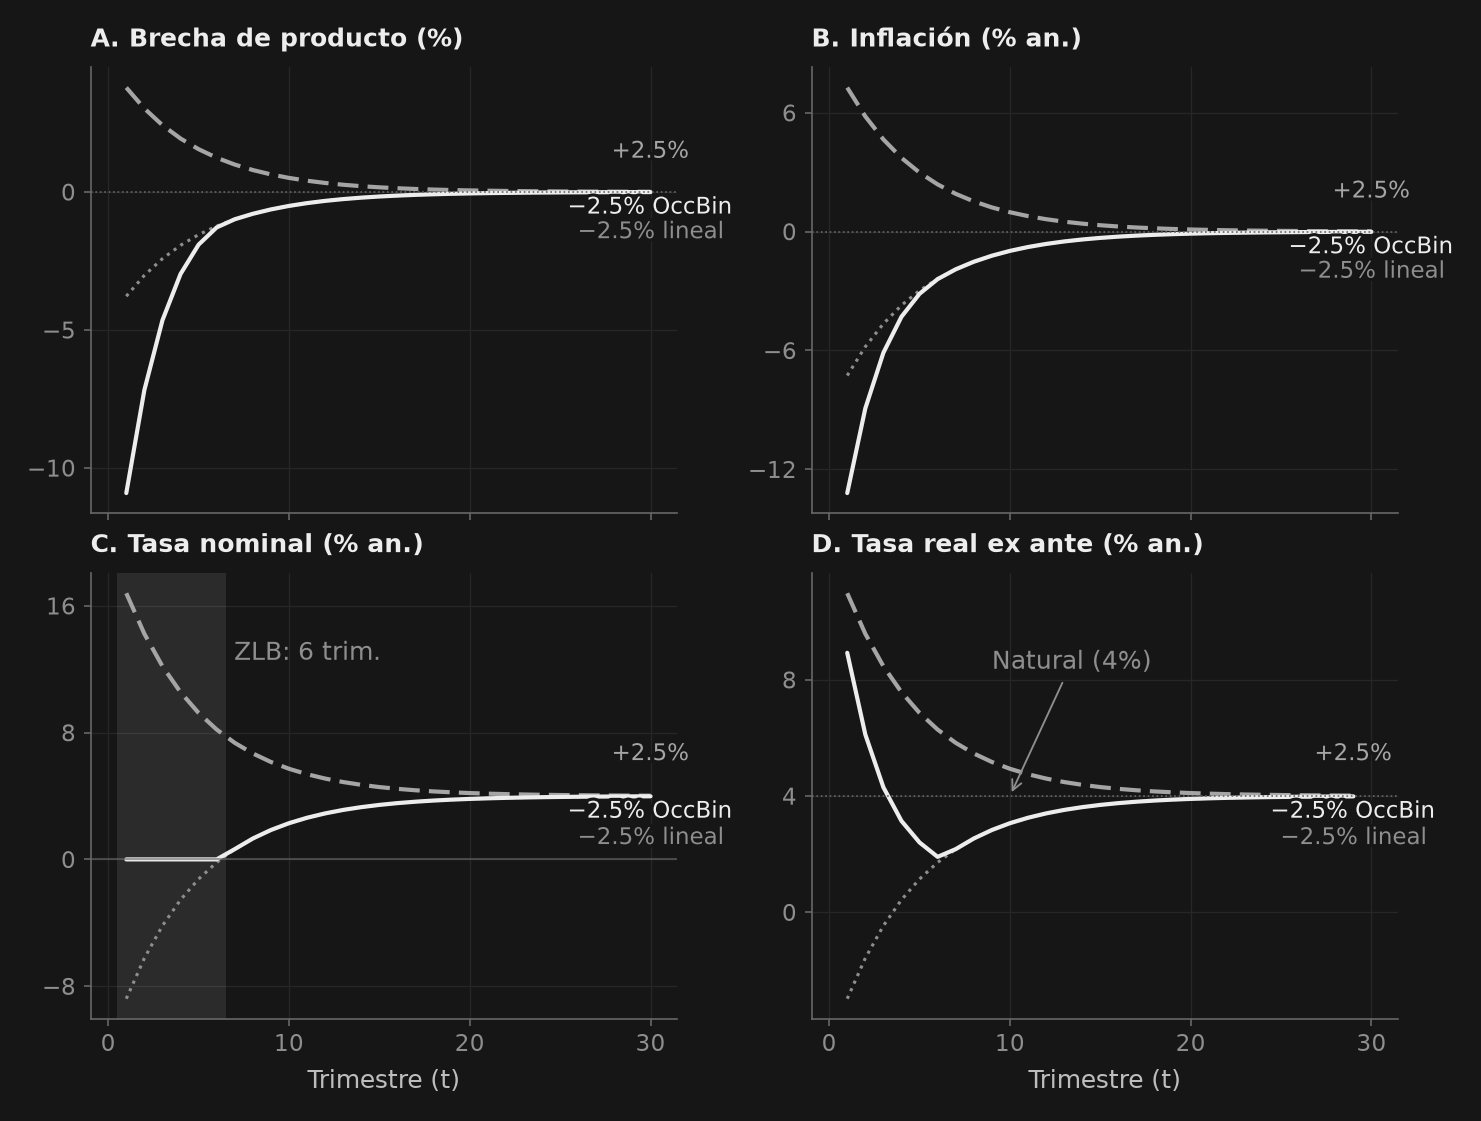

In [3]:
# ==============================================================================
# Simulación 1: Laboratorio de Asimetría de Choques (+2.5% vs -2.5%)
# ==============================================================================
horizon = 30
shock_size = 0.025  # Choque de demanda del 2.5%

# 1. Soluciones OccBin Lineales por Partes
shock_pos = np.array([0.0, shock_size])
shock_neg = np.array([0.0, -shock_size])

res_pos = solve_occbin(ref_model, cons_model, constraint, shock_sequence=shock_pos, horizon=horizon)
res_neg = solve_occbin(ref_model, cons_model, constraint, shock_sequence=shock_neg, horizon=horizon)

# 2. Contrafactual Lineal Puro (Regla de Taylor permitiendo tasas negativas)
dr = ref_model.decision_rules()
P_0 = np.zeros((len(ref_model.variables), len(ref_model.variables)))
for s in ref_model.states:
    idx_s = list(ref_model.variables).index(s)
    P_0[:, idx_s] = dr.ghx[s].values

lin_neg = np.zeros((horizon, len(ref_model.variables)))
lin_neg[0] = dr.ghu.values @ shock_neg
for t in range(1, horizon):
    lin_neg[t] = P_0 @ lin_neg[t - 1]

lin_df = pd.DataFrame(lin_neg, columns=ref_model.variables)

# Marcador Cuantitativo
y_pos_0 = res_pos["y"].iloc[0] * 100
r_pos_0 = (r_ss + res_pos["r"].iloc[0]) * 400
y_neg_0 = res_neg["y"].iloc[0] * 100
r_neg_0 = (r_ss + res_neg["r"].iloc[0]) * 400
y_lin_0 = lin_df["y"].iloc[0] * 100
r_lin_0 = (r_ss + lin_df["r"].iloc[0]) * 400

asymmetry_ratio = abs(y_neg_0) / y_pos_0
zlb_penalty = abs(y_neg_0) - abs(y_lin_0)

print("=" * 76)
print("MARCADOR DE ASIMETRÍA MACROECONÓMICA ANTE CHOQUES (IMPACTO T=1)")
print("=" * 76)
print(f"Demanda Positiva (+2.5%) : Brecha de Producto = {y_pos_0:+6.2f}%, Tasa Política = {r_pos_0:6.2f}% an. (Periodos ZLB: {res_pos.binding_periods})")
print(f"Lineal Negativo (-2.5%)  : Brecha de Producto = {y_lin_0:+6.2f}%, Tasa Política = {r_lin_0:6.2f}% an. (Sombra no restringida)")
print(f"OccBin Negativo (-2.5%)  : Brecha de Producto = {y_neg_0:+6.2f}%, Tasa Política = {r_neg_0:6.2f}% an. (Periodos ZLB: {res_neg.binding_periods})")
print("-" * 76)
print(f"Ratio de Asimetría (|y_neg| / y_pos) : {asymmetry_ratio:.2f}x (El modelo lineal es idénticamente 1.00x)")
print(f"Penalización ZLB vs Lineal          : {zlb_penalty:.2f} puntos porcentuales más de recesión")
print("=" * 76)

# Verificación de la Secuencia Binaria de Regímenes y Límite Inferior Cero
print("\n" + "=" * 76)
print("DINÁMICA BINARIA DE TRANSICIÓN DE REGÍMENES EN OCCBIN")
print("=" * 76)
print(f"Secuencia Histórica de Regímenes (0=Referencia, 1=ZLB Activo):")
print(f"  {res_neg.regimes}")
print(f"Trimestres Totales en el ZLB: {res_neg.binding_periods} trimestres")
print(f"Régimen Terminal: {res_neg.regimes[-1]} (retorno suave al régimen de referencia)")
print(f"Desviación Mínima de Tasa Política: {res_neg['r'].min():.6f} (Piso ZLB: {-r_ss:.6f})")
print("=" * 76)

assert res_neg.converged is True, "Las iteraciones de régimen de OccBin deben converger."
assert res_neg.regimes[-1] == 0, "El régimen terminal debe retornar al régimen de referencia no restringido."
assert np.all(res_neg["r"].values >= -r_ss - 1e-10), "Violación del piso ZLB: r_t cayó por debajo de -r_ss!"

# Visualización
from matplotlib.ticker import MaxNLocator

time = np.arange(1, horizon + 1)

# El arnés de láminas fija rcParams["figure.figsize"] a la ranura ANTES de dibujar.
# Heredarla es lo que hace que la misma celda sirva para las dos lecturas: si la
# figura se dibujara al tamaño del cuaderno y se encogiera después, las anotaciones
# se quedarían donde estaban los ejes viejos. En el cuaderno vale el 2x2 de la casa.
_ranura = tuple(plt.rcParams["figure.figsize"]) if os.environ.get("MAV_NB_PERFIL") == "lamina" else None
fig, axes = _nbstyle.figura(2, 2, sharex=True, figsize=_ranura)

# A ancho de ranura la columna mide ~2,6 in: siete marcas por eje se amontonan.
for _ax in axes.flat:
    _ax.xaxis.set_major_locator(MaxNLocator(4, integer=True))
    _ax.yaxis.set_major_locator(MaxNLocator(4))

# La contrafactual lineal va más fina que las dos sendas OccBin en los dos perfiles.
lw_lin = plt.rcParams["lines.linewidth"] * 0.75

# Las unidades viajan en el título del panel: a 2,6 in de columna un rótulo de eje
# vertical es más alto que el propio panel y se recorta.
ETIQ = ("+2.5%", "−2.5% lineal", "−2.5% OccBin")

# Panel A: Brecha de Producto
ax = axes[0, 0]
ax.plot(time, res_pos["y"] * 100, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time, lin_df["y"] * 100, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time, res_neg["y"] * 100, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_title("A. Brecha de producto (%)")
_nbstyle.etiquetar(ax)

# Panel B: Inflación Anualizada
ax = axes[0, 1]
ax.plot(time, res_pos["pi"] * 400, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time, lin_df["pi"] * 400, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time, res_neg["pi"] * 400, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_title("B. Inflación (% an.)")
_nbstyle.etiquetar(ax)

# Panel C: Tasa de Política Nominal (Nivel Anualizado)
ax = axes[1, 0]
ax.plot(time, (r_ss + res_pos["r"]) * 400, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time, (r_ss + lin_df["r"]) * 400, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time, (r_ss + res_neg["r"]) * 400, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=1.0, alpha=0.6)
ax.axvspan(0.5, res_neg.binding_periods + 0.5, color=_nbstyle.RECESION, lw=0)
ax.annotate(f"ZLB: {res_neg.binding_periods} trim.", xy=(res_neg.binding_periods + 0.5, 13.0),
            xytext=(4, 0), textcoords="offset points", ha="left", va="center", color=_nbstyle.NOTA)
ax.set_xlabel("Trimestre (t)")
ax.set_title("C. Tasa nominal (% an.)")
_nbstyle.etiquetar(ax)

# Panel D: Tasa de Interés Real Ex-Ante
ax = axes[1, 1]
r_real_pos = (res_pos["r"].iloc[:-1].values - res_pos["pi"].iloc[1:].values + r_ss) * 400
r_real_lin = (lin_df["r"].iloc[:-1].values - lin_df["pi"].iloc[1:].values + r_ss) * 400
r_real_neg = (res_neg["r"].iloc[:-1].values - res_neg["pi"].iloc[1:].values + r_ss) * 400

ax.plot(time[:-1], r_real_pos, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time[:-1], r_real_lin, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time[:-1], r_real_neg, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(r_ss * 400, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# La recta natural se nombra desde el hueco de arriba: junto a su trazo la tapan las tres sendas
ax.annotate(f"Natural ({r_ss * 400:.0f}%)", xy=(10.0, r_ss * 400), xytext=(9.0, 8.6),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Trimestre (t)")
ax.set_title("D. Tasa real ex ante (% an.)")
_nbstyle.etiquetar(ax)

plt.show()


## 3. Sección 2: La Super-Amplificación del Multiplicador Fiscal en el Límite Inferior Cero

Un resultado fundamental en la teoría de política macroeconómica (Christiano, Eichenbaum & Rebelo 2011, *JPE*; Eggertsson 2011; Woodford 2011) concierne la **dependencia de estado del multiplicador del gasto público**:

$$\text{Multiplicador} = \frac{\partial Y_t}{\partial G_t}$$

### Canales de Transmisión: Expulsión vs. Atracción de Inversión
1. **Tiempos Normales (Regla de Taylor Activa)**:
   - Al incrementar el gasto público $G_t \uparrow$, aumentan la demanda agregada y la inflación.
   - Como la política monetaria cumple el Principio de Taylor ($\phi_\pi = 1.5 > 1$), el banco central sube la tasa nominal $i_t$ más que proporcionalmente.
   - La **tasa de interés real aumenta** ($r_t^{\text{real}} \uparrow$), desincentivando el consumo presente y la inversión. El gasto privado es **expulsado** (*crowding out*), manteniendo el multiplicador moderado (en la literatura, $\sim 0.7 - 0.9$; en este modelo, $1.5$).

2. **Trampa de Liquidez (Piso de Cero Activo)**:
   - En el ZLB, la tasa nominal se encuentra clavada en cero ($i_t = 0$).
   - El estímulo fiscal genera expectativas de inflación futura ($\mathbb{E}_t \pi_{t+1} \uparrow$).
   - Al no poder subir la tasa nominal, la **tasa real cae directamente**:
     $$\Delta r_{t}^{\text{real}} = 0 - \Delta \mathbb{E}_t \pi_{t+1} < 0$$
   - La caída de la tasa real estimula el gasto privado (*crowding in*), provocando que el multiplicador fiscal **se dispare muy por encima de 2.0** (en este modelo, $6.8$)!

COMPARACIÓN DEL MULTIPLICADOR DE GASTO FISCAL
Multiplicador Fiscal en Tiempos Normales (Regla Taylor activa) :  1.512
Multiplicador en Trampa de Liquidez ZLB (Tasa nominal fija)    :  6.838
Ratio de Amplificación del Multiplicador                      :   4.52x


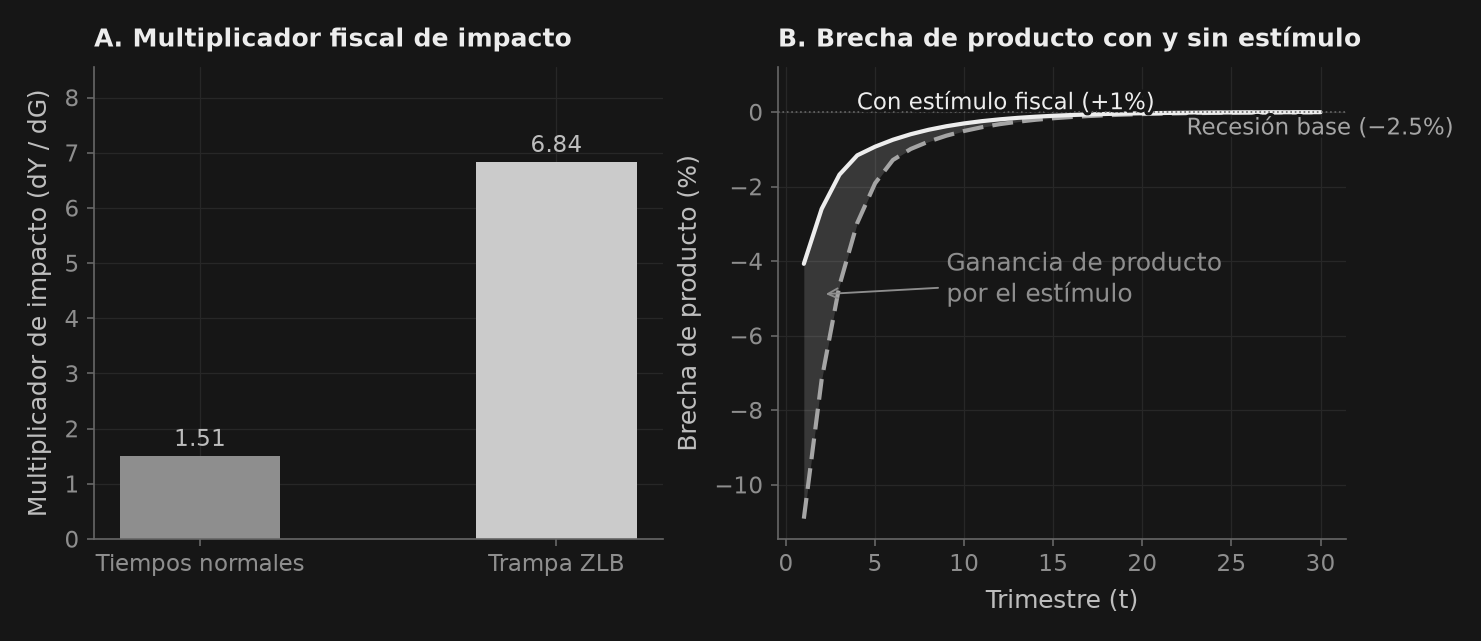

In [4]:
# ==============================================================================
# Simulación 2: Comparación del Multiplicador Fiscal (Tiempos Normales vs ZLB)
# ==============================================================================
stimulus_size = 0.01  # Estímulo fiscal de +1% del PIB

# 1. Multiplicador en Tiempos Normales
res_normal_base = solve_occbin(ref_model, cons_model, constraint, shock_sequence=np.array([0.0, 0.0]), horizon=horizon)
res_normal_stim = solve_occbin(ref_model, cons_model, constraint, shock_sequence=np.array([0.0, stimulus_size]), horizon=horizon)
multiplier_normal = (res_normal_stim["y"].iloc[0] - res_normal_base["y"].iloc[0]) / stimulus_size

# 2. Multiplicador en Trampa de Liquidez (ZLB)
res_zlb_base = res_neg  # Choque recesivo de -2.5%
shock_zlb_stim = np.array([0.0, -shock_size + stimulus_size])  # Choque neto de -1.5%
res_zlb_stim = solve_occbin(ref_model, cons_model, constraint, shock_sequence=shock_zlb_stim, horizon=horizon)
multiplier_zlb = (res_zlb_stim["y"].iloc[0] - res_zlb_base["y"].iloc[0]) / stimulus_size

amplification = multiplier_zlb / multiplier_normal

print("=" * 76)
print("COMPARACIÓN DEL MULTIPLICADOR DE GASTO FISCAL")
print("=" * 76)
print(f"Multiplicador Fiscal en Tiempos Normales (Regla Taylor activa) : {multiplier_normal:6.3f}")
print(f"Multiplicador en Trampa de Liquidez ZLB (Tasa nominal fija)    : {multiplier_zlb:6.3f}")
print(f"Ratio de Amplificación del Multiplicador                      : {amplification:6.2f}x")
print("=" * 76)

# Visualización
fig, (ax1, ax2) = _nbstyle.figura(1, 2)

# Gráfico de barras
ax1.bar(["Tiempos normales", "Trampa ZLB"], [multiplier_normal, multiplier_zlb], color=[_nbstyle.BARRA_COLORES[1], _nbstyle.BARRA_COLORES[0]], width=0.45)
ax1.set_ylabel("Multiplicador de impacto (dY / dG)")
ax1.set_title("A. Multiplicador fiscal de impacto")
ax1.set_ylim(0, max(multiplier_normal, multiplier_zlb) * 1.25)
_nbstyle.etiquetar_barras(ax1, fmt="{:.2f}")

# Trayectorias dinámicas con y sin estímulo
ax2.plot(time, res_zlb_base["y"] * 100, label="Recesión base (−2.5%)", **_nbstyle.S2)
ax2.plot(time, res_zlb_stim["y"] * 100, label="Con estímulo fiscal (+1%)", **_nbstyle.S1)
ax2.fill_between(time, res_zlb_base["y"] * 100, res_zlb_stim["y"] * 100, color=_nbstyle.BANDA, lw=0)
ax2.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax2.set_ylim(top=1.2)
ax2.annotate("Ganancia de producto\npor el estímulo", xy=(time[1], (res_zlb_base["y"].iloc[1] + res_zlb_stim["y"].iloc[1]) * 50),
             xytext=(9.0, -4.5), ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax2.set_xlabel("Trimestre (t)")
ax2.set_ylabel("Brecha de producto (%)")
ax2.set_title("B. Brecha de producto con y sin estímulo")
_nbstyle.etiquetar(ax2)

plt.show()


## 4. Sección 3: Duración Endógena $T^*$ y la Monotonía de la Espiral Deflacionaria

A diferencia de los enfoques ad-hoc con duración prefijada, el algoritmo de Guerrieri & Iacoviello (2015) no asume cuántos periodos permanece la economía atrapada en cero. La duración $T^*$ es un **resultado endógeno de expectativas racionales**:

$$T^* = \min \left\{ t \ge 1 \;\Big|\; i_t^{\text{sombra}} \ge -r_{ss} \right\}$$

### La Aceleración de la Espiral Deflacionaria
A medida que el choque de demanda se vuelve progresivamente más severo:
1. La duración $T^*$ escala discretamente (de 0 a 2, 3, 5, 6 y 7 trimestres).
2. Cada trimestre adicional en el ZLB agrava la deflación esperada en la Curva de Phillips:
   $$\pi_t = \sum_{j=0}^{T^*} \beta^j \kappa y_{t+j} + \beta^{T^*+1} \mathbb{E}_t \pi_{t+T^*+1}$$
3. Dado que la mayor deflación esperada incrementa la tasa de interés real actual, el colapso del producto se acelera de forma **no-lineal** más allá de un umbral crítico.

BARRIDO DE MONOTONÍA Y ESPIRAL DEFLACIONARIA EN OCCBIN
 Choque (%)  Duración ZLB T* (trim)  Valle Producto (%)  Valle Inflación (% an.)  Convergencia  Iteraciones
    -0.5               0                  -0.755814             -1.453488             True          1      
    -1.0               2                  -1.816279             -3.038047             True          2      
    -1.5               3                  -4.072749             -5.483027             True          2      
    -2.0               5                  -7.179398             -8.927097             True          2      
    -2.5               6                 -10.911173            -13.202295             True          2      
    -3.0               7                 -15.127353            -18.148273             True          2      
    -3.5               7                 -19.964928            -23.975065             True          2      


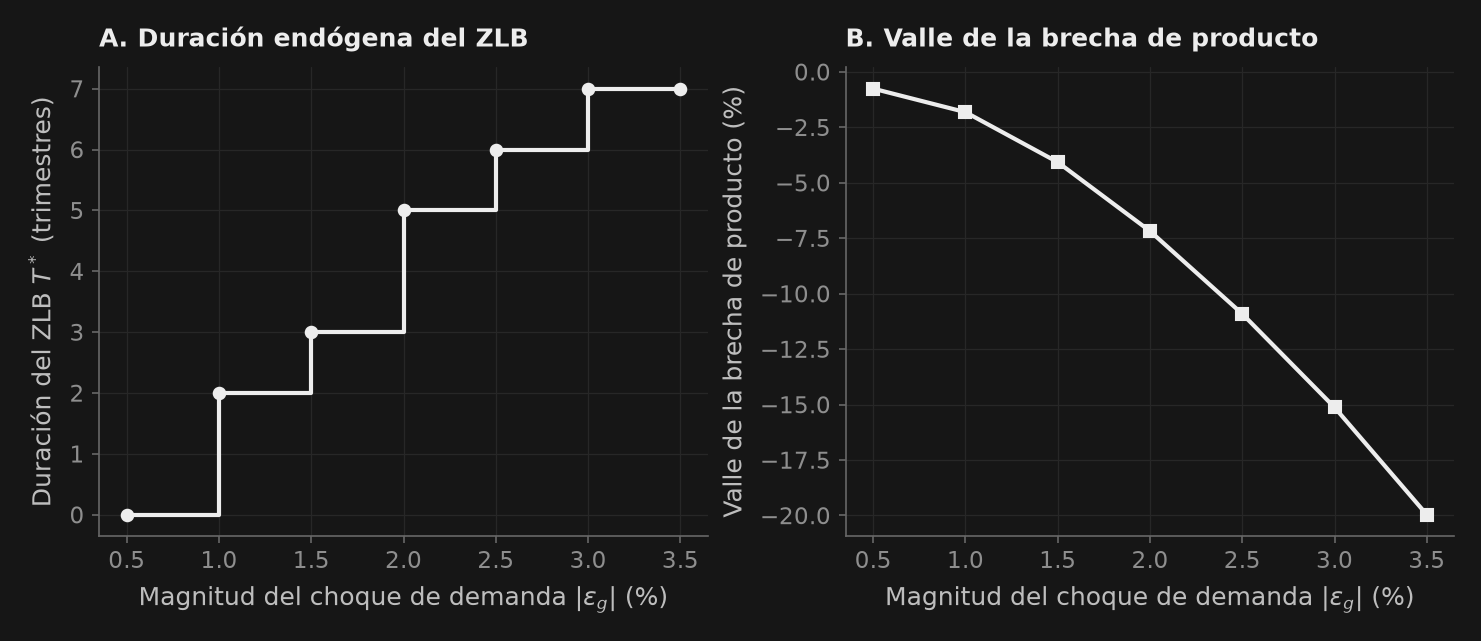

In [5]:
# ==============================================================================
# Simulación 3: Barrido Paramétrico de Choques y Duración del ZLB
# ==============================================================================
shock_grid = np.linspace(-0.005, -0.035, 7)  # -0.5% a -3.5%
sweep_results = []

for s in shock_grid:
    res_s = solve_occbin(ref_model, cons_model, constraint, shock_sequence=np.array([0.0, s]), horizon=horizon)
    y_min = res_s["y"].min() * 100
    pi_min = res_s["pi"].min() * 400
    sweep_results.append({
        "Choque (%)": s * 100,
        "Duración ZLB T* (trim)": res_s.binding_periods,
        "Valle Producto (%)": y_min,
        "Valle Inflación (% an.)": pi_min,
        "Convergencia": res_s.converged,
        "Iteraciones": res_s.iterations,
    })

sweep_df = pd.DataFrame(sweep_results)

print("=" * 76)
print("BARRIDO DE MONOTONÍA Y ESPIRAL DEFLACIONARIA EN OCCBIN")
print("=" * 76)
print(sweep_df.to_string(index=False, justify="center"))
print("=" * 76)

# Visualización de la no-linealidad en duración y producto
fig, (ax1, ax2) = _nbstyle.figura(1, 2)

ax1.step(abs(sweep_df["Choque (%)"]), sweep_df["Duración ZLB T* (trim)"], where="post", marker="o", **_nbstyle.S1)
ax1.set_xlabel("Magnitud del choque de demanda $|\\varepsilon_g|$ (%)")
ax1.set_ylabel("Duración del ZLB $T^*$ (trimestres)")
ax1.set_title("A. Duración endógena del ZLB")

ax2.plot(abs(sweep_df["Choque (%)"]), sweep_df["Valle Producto (%)"], marker="s", **_nbstyle.S1)
ax2.set_xlabel("Magnitud del choque de demanda $|\\varepsilon_g|$ (%)")
ax2.set_ylabel("Valle de la brecha de producto (%)")
ax2.set_title("B. Valle de la brecha de producto")

plt.show()


## 5. Sección 4: Orientación Hacia Adelante (*Forward Guidance*) y Compromisos Monetarios

Cuando la tasa nominal está paralizada en cero, las operaciones de mercado abierto pierden tracción directa sobre las tasas de interés. Frente a ello, los bancos centrales modernos recurren a la **Orientación Hacia Adelante** (*Forward Guidance*, Eggertsson & Woodford 2003, Del Negro, Giannoni & Patterson 2015):

> *"El banco central se compromete a mantener la tasa de interés en cero incluso después de que la tasa natural se haya recuperado y los fundamentos macroeconómicos justificarían un alza de tasas."*

### El Mecanismo Económico del Forward Guidance
- Bajo expectativas racionales, prometer tasas de interés en cero en periodos futuros $T^*+1$ genera **expectativas de inflación futura** ($\mathbb{E}_t \pi_{T^*+1} > 0$) y un auge económico anticipado ($\mathbb{E}_t y_{T^*+1} > 0$).
- Por el descuento hacia atrás en la ecuación de Euler y la curva de Phillips, estas expectativas futuras **reducen inmediatamente las tasas reales hoy**:
  $$y_t = \mathbb{E}_t y_{T^*+2} - \frac{1}{\sigma} \sum_{j=0}^{T^*+1} \left(r_{t+j} - \mathbb{E}_t \pi_{t+j+1}\right)$$
- Por consiguiente, un compromiso creíble de mantener tasas bajas por más tiempo estimula el producto y frena la deflación en $t=1$ ¡sin necesidad de mover la tasa actual un solo punto base!

Episodio de ZLB base: 6 trimestres -> tasa en cero hasta t=7
Episodio de ZLB bajo el compromiso: 7 trimestres
EXPERIMENTO DE POLÍTICA: FORWARD GUIDANCE
Brecha de Producto con Salida Estándar (t=1)     : -10.91%
Brecha con Compromiso de Forward Guidance (t=1)  : -10.29%
Protección del Producto por Forward Guidance     :  +0.62 puntos porcentuales


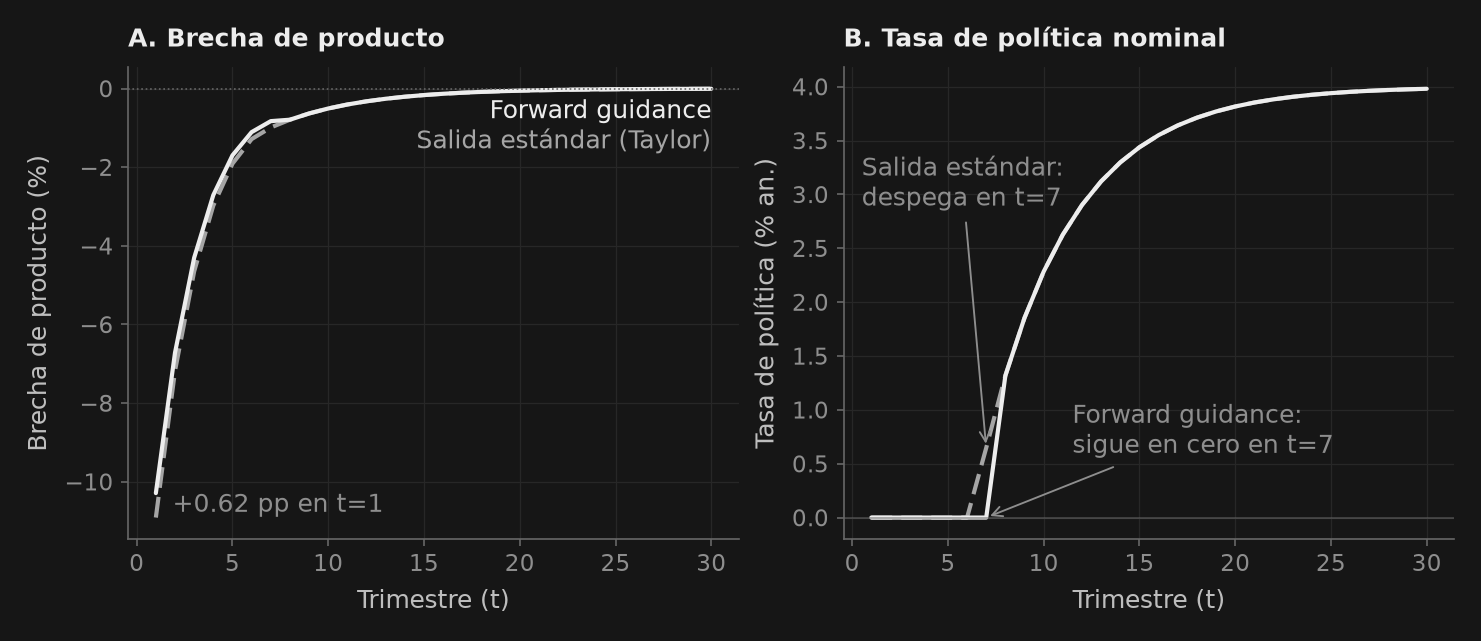

In [6]:
# ==============================================================================
# Simulación 4: Compromiso de Forward Guidance vs Salida Estándar de Taylor
# ==============================================================================
# Salida estándar: el episodio de ZLB del choque de -2.5% de la Sección 1 y retorno automático a regla de Taylor
res_standard = res_neg

# Forward guidance: el compromiso tiene que morder DESPUÉS de que la regla habría despegado.
# Mientras la restricción ata, la tasa de política está clavada en -r_ss, así que un choque
# expansivo colocado dentro de la ventana de atadura lo absorbe exactamente el clavo y no
# cambia nada — que es justamente el contenido de «al banco central se le acabó el margen».
# «Lower for longer» significa comprometerse a mantener la tasa en cero hasta el primer
# trimestre en que la regla de Taylor habría empezado a subir, lo que alarga el episodio de
# ZLB un trimestre y opera hacia atrás por la ecuación de Euler sobre el producto de hoy. El
# compromiso tiene que cubrir todo el episodio alargado, no solo el trimestre extra: la tasa
# cero prometida en el despegue eleva la inflación del trimestre anterior, y una regla libre
# ahí despega un trimestre y luego vuelve a recortar a cero — dos episodios en vez de uno más
# largo. Donde el piso ata, el clavo absorbe el recorte, así que su tamaño solo tiene que
# mantener la tasa nocional por debajo del piso.
liftoff_idx = int(res_standard.binding_periods)   # primer trimestre en que la regla despegaría

fg_shocks = np.zeros((horizon, 2))
fg_shocks[0, 1] = -0.025                  # Choque de demanda adverso en t=1
fg_shocks[:liftoff_idx + 1, 0] = -0.005   # Compromiso de mantener la tasa en cero hasta el despegue, anunciado en t=1

res_fg = solve_occbin(ref_model, cons_model, constraint, shock_sequence=fg_shocks, horizon=horizon)

# Duración del episodio de ZLB que abre en t=1 (índice del primer trimestre sin atar).
# `binding_periods` cuenta todos los trimestres que atan, así que solo es la duración si no hay hueco.
spell_standard = int(np.argmin(res_standard.regimes))
spell_fg = int(np.argmin(res_fg.regimes))

print(f"Episodio de ZLB base: {spell_standard} trimestres -> tasa en cero hasta t={liftoff_idx + 1}")
print(f"Episodio de ZLB bajo el compromiso: {spell_fg} trimestres")

print("=" * 76)
print("EXPERIMENTO DE POLÍTICA: FORWARD GUIDANCE")
print("=" * 76)
print(f"Brecha de Producto con Salida Estándar (t=1)     : {res_standard['y'].iloc[0] * 100:6.2f}%")
print(f"Brecha con Compromiso de Forward Guidance (t=1)  : {res_fg['y'].iloc[0] * 100:6.2f}%")
print(f"Protección del Producto por Forward Guidance     : {(res_fg['y'].iloc[0] - res_standard['y'].iloc[0]) * 100:+6.2f} puntos porcentuales")
print("=" * 76)

assert res_fg.converged is True, "La senda de forward guidance debe ser una solución verificada de OccBin."
# Un solo episodio desde t=1 en cada senda: ningún trimestre ata después del primero sin atar.
assert res_standard.binding_periods == spell_standard, f"La senda base tiene un segundo episodio de ZLB: {res_standard.regimes}"
assert res_fg.binding_periods == spell_fg, (
    f"El «lower for longer» debe mantener la tasa en el piso sin interrupciones: {res_fg.regimes}"
)
assert spell_fg == spell_standard + 1, (
    "El «lower for longer» debe alargar el episodio de ZLB exactamente un trimestre más allá del despegue de Taylor."
)
assert res_fg["y"].iloc[0] > res_standard["y"].iloc[0], (
    "Un compromiso creíble de acomodar en el despegue debe elevar el producto en el impacto."
)

fig, (ax1, ax2) = _nbstyle.figura(1, 2, sharex=True)

y_std_0 = res_standard["y"].iloc[0] * 100
y_fg_0 = res_fg["y"].iloc[0] * 100
ax1.plot(time, res_standard["y"] * 100, **_nbstyle.S2)
ax1.plot(time, res_fg["y"] * 100, **_nbstyle.S1)
ax1.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# Las dos sendas solo se separan en el impacto: la diferencia se anota ahí
ax1.annotate(f"{y_fg_0 - y_std_0:+.2f} pp en t=1", xy=(time[0], (y_std_0 + y_fg_0) / 2), xytext=(8, 0),
             textcoords="offset points", ha="left", va="center", color=_nbstyle.NOTA)
ax1.set_xlabel("Trimestre (t)")
ax1.set_ylabel("Brecha de producto (%)")
ax1.set_title("A. Brecha de producto")
# Las sendas se funden tras el despegue: sus nombres van bajo el extremo común, cada uno en el gris de su trazo
ax1.annotate("Forward guidance", xy=(time[-1], res_fg["y"].iloc[-1] * 100), xytext=(0, -5), textcoords="offset points",
             ha="right", va="top", color=_nbstyle.S1["color"])
ax1.annotate("Salida estándar (Taylor)", xy=(time[-1], res_standard["y"].iloc[-1] * 100), xytext=(0, -19), textcoords="offset points",
             ha="right", va="top", color=_nbstyle.S2["color"])

r_std_lev = (r_ss + res_standard["r"]) * 400
r_fg_lev = (r_ss + res_fg["r"]) * 400
ax2.plot(time, r_std_lev, **_nbstyle.S2)
ax2.plot(time, r_fg_lev, **_nbstyle.S1)
ax2.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=0.8, alpha=0.6)
# Las sendas solo difieren en el trimestre del despegue de Taylor: cada una se nombra ahí
ax2.annotate(f"Salida estándar:\ndespega en t={liftoff_idx + 1}", xy=(time[liftoff_idx], r_std_lev.iloc[liftoff_idx]),
             xytext=(0.5, 3.1), ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax2.annotate(f"Forward guidance:\nsigue en cero en t={liftoff_idx + 1}", xy=(time[liftoff_idx], r_fg_lev.iloc[liftoff_idx]),
             xytext=(11.5, 0.8), ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax2.set_xlabel("Trimestre (t)")
ax2.set_ylabel("Tasa de política (% an.)")
ax2.set_title("B. Tasa de política nominal")

plt.show()


## 6. Sección 5: OccBin Multi-Restricción — Límite Inferior Cero y Restricciones de Colateral Simultáneas (4 Regímenes)

En crisis macroeconómicas severas (como la Gran Crisis Financiera de 2008 o los episodios de *Sudden Stop* en economías emergentes), las economías rara vez enfrentan una sola fricción aislada. Por el contrario, colisionan dos no-linealidades fundamentales de forma simultánea:
1. **Límite Inferior Cero Monetario (ZLB)**: La tasa de interés nominal no puede descender por debajo de cero ($r_t \ge -r_{ss}$).
2. **Restricción de Garantías y Endeudamiento Privado**: El apalancamiento o crédito bancario no puede rebasar un tope físico o colateral ($b_t \le \bar{b}$).

### El Espacio Combinatorio de $2^K$ Regímenes
Cuando $K \ge 2$ restricciones pueden activarse ocasionalmente, el espacio de estados se fragmenta en $2^K$ regímenes discretos. Para $K=2$, se obtienen **4 regímenes macroeconómicos bien definidos**:

| ID de Régimen | Máscara Binaria | Restricción ZLB ($r_t$) | Límite de Crédito ($b_t$) | Descripción Macroeconómica |
|---|---|---|---|---|
| **Régimen 0** | `(0, 0)` | Inactiva ($r_t > -r_{ss}$) | Inactiva ($b_t < \bar{b}$) | **Referencia No Restringida**: Regla de Taylor activa y crédito holgado. |
| **Régimen 1** | `(1, 0)` | **Activa** ($r_t = -r_{ss}$) | Inactiva ($b_t < \bar{b}$) | **Trampa de Liquidez Pura**: Tasa anclada al piso; crédito fluido. |
| **Régimen 2** | `(0, 1)` | Inactiva ($r_t > -r_{ss}$) | **Activa** ($b_t = \bar{b}$) | **Fricción Crediticia Pura**: Deuda topada; banco central ajusta tasas. |
| **Régimen 3** | `(1, 1)` | **Activa** ($r_t = -r_{ss}$) | **Activa** ($b_t = \bar{b}$) | **Doble Trampa Financiero-Monetaria**: ¡Parálisis crediticia y monetaria! |

### Recursión Hacia Atrás Multi-Régimen en `puremacro`
La función `solve_multiconstraint_occbin` de puremacro resuelve este sistema combinatorio mediante:
1. Precomputación exacta de matrices estructurales $(A^+_r, A^0_r, A^-_r, B^u_r, c_r)$ para los $2^K = 4$ regímenes sin reinversión matricial redundante.
2. Recursión hacia atrás desde el horizonte terminal $T$ determinando las reglas de decisión dependientes del tiempo $P_t(\mathcal{R}), D_t(\mathcal{R})$.
3. Actualización simultánea de los multiplicadores sombra de Kuhn-Tucker ($r^{\text{sombra}}_t$ y $b^{\text{sombra}}_t$) con amortiguamiento (*damping*) ante oscilaciones.
4. Identificación endógena de la trayectoria de regímenes: por ejemplo, comenzando en doble trampa (Régimen 3), aliviando el colateral para quedar en ZLB (Régimen 1), y retornando a la normalidad (Régimen 0).

MARCADOR DE SIMULACIÓN OCCBIN MULTI-RESTRICCIÓN (4 REGÍMENES)
Convergencia del Algoritmo : True (en 3 iteraciones de punto fijo)
Secuencia Realizada de Regímenes:
  [3, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Regímenes Visitados        : [0, 1, 3] (3=Doble trampa, 1=Solo ZLB, 0=Holgura)
Periodos Totales Activos   : 3 trimestres
Mínimo de Tasa Política    : -0.015000 (Piso ZLB: -0.015000)
Pico de Deuda Privada      : 0.020000 (Tope de Deuda: 0.020000)

Tabla de Trayectoria Multi-Restricción (Formato Markdown):
|       y |      pi |       r |       b |       g |
|---------|---------|---------|---------|---------|
| -0.1464 | -0.0450 | -0.0150 |  0.0200 | -0.0600 |
| -0.0762 | -0.0232 | -0.0150 | -0.0052 | -0.0420 |
| -0.0378 | -0.0119 | -0.0150 | -0.0102 | -0.0294 |
| -0.0182 | -0.0063 | -0.0146 | -0.0087 | -0.0206 |
| -0.0095 | -0.0036 | -0.0119 | -0.0063 | -0.0144 |
| -0.0053 | -0.0022 | -0.0090 | -0.0042 | -0.0101 |
| -0.0032 | -0.0014 | 

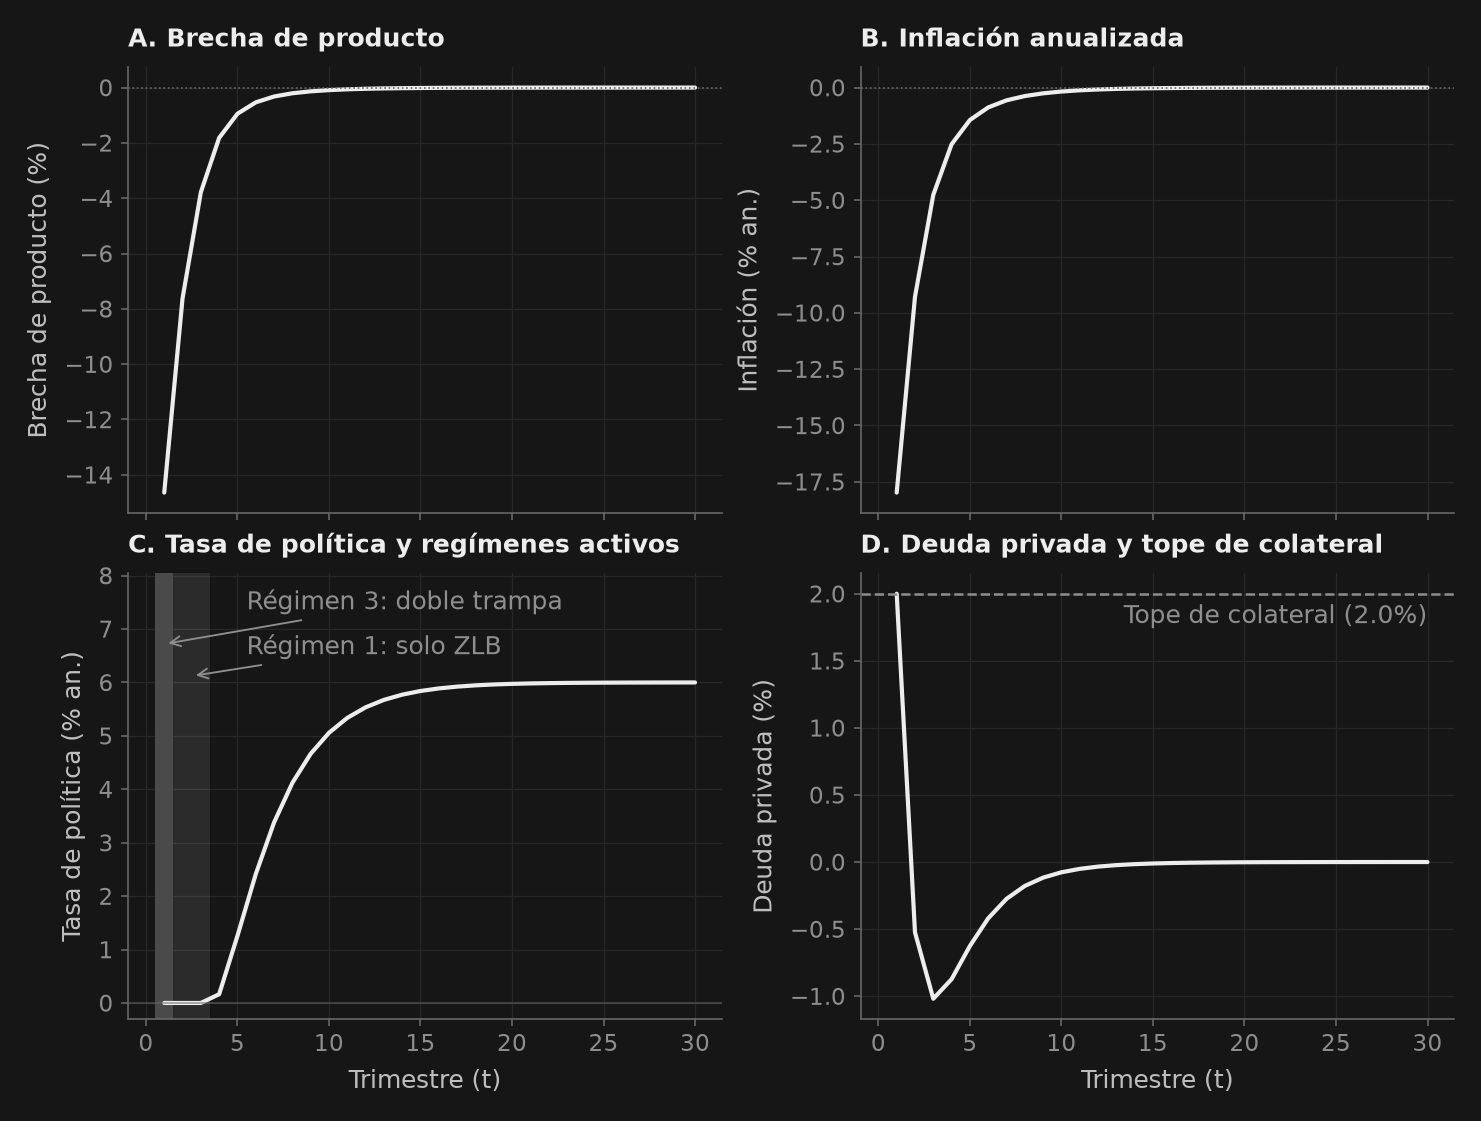

In [7]:
# ==============================================================================
# Simulación 5: Dinámica OccBin Multi-Restricción y Recorrido de los 4 Regímenes
# ==============================================================================
from puremacro.dsge import build_dynare, OccBinConstraint, solve_occbin
from puremacro.dsge.occbin import solve_multiconstraint_occbin

# Especificación de un modelo Nuevo Keynesiano de 5 ecuaciones con crédito endógeno:
# Variables: y (brecha de producto), pi (inflación), r (tasa política), b (deuda privada), g (demanda)
# Shocks: eps_g (demanda), eps_r (monetario), eps_b (expansión de crédito)
params_mc = {
    "beta": 0.99,
    "sigma": 1.0,
    "kappa": 0.15,
    "phi_pi": 1.5,
    "phi_y": 0.25,
    "rho_r": 0.6,
    "rho_b": 0.5,
    "rho_g": 0.7,
    "gamma_y": 0.2,
    "chi": 0.1,
    "r_ss": 0.015,
    "b_bar": 0.02,
}

variables_mc = ["y", "pi", "r", "b", "g"]
shocks_mc = ["eps_g", "eps_r", "eps_b"]
steady_state_mc = {v: 0.0 for v in variables_mc}

# Régimen 0: Modelo de referencia (Regla Taylor activa, crédito holgado)
def ref_eqs_mc(lead, curr, lag, shocks_v, p):
    return [
        curr.y - lead.y + (curr.r - lead.pi) / p.sigma - curr.g + p.chi * curr.b,
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.r - (p.rho_r * lag.r + (1.0 - p.rho_r) * (p.phi_pi * curr.pi + p.phi_y * curr.y) + shocks_v.eps_r),
        curr.b - (p.rho_b * lag.b + p.gamma_y * curr.y + shocks_v.eps_b),
        curr.g - p.rho_g * lag.g - shocks_v.eps_g,
    ]

# Régimen 1: ZLB activo (r anclada a -r_ss, crédito holgado)
def zlb_eqs_mc(lead, curr, lag, shocks_v, p):
    return [
        curr.y - lead.y + (curr.r - lead.pi) / p.sigma - curr.g + p.chi * curr.b,
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.r - (-p.r_ss),
        curr.b - (p.rho_b * lag.b + p.gamma_y * curr.y + shocks_v.eps_b),
        curr.g - p.rho_g * lag.g - shocks_v.eps_g,
    ]

# Régimen 2: Límite de crédito activo (b anclada a b_bar, Regla Taylor activa)
def borr_eqs_mc(lead, curr, lag, shocks_v, p):
    return [
        curr.y - lead.y + (curr.r - lead.pi) / p.sigma - curr.g + p.chi * curr.b,
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.r - (p.rho_r * lag.r + (1.0 - p.rho_r) * (p.phi_pi * curr.pi + p.phi_y * curr.y) + shocks_v.eps_r),
        curr.b - p.b_bar,
        curr.g - p.rho_g * lag.g - shocks_v.eps_g,
    ]

# Compilación mediante puremacro build_dynare
m_uncons_mc = build_dynare(ref_eqs_mc, variables=variables_mc, shocks=shocks_mc, params=params_mc, steady_state=steady_state_mc)
m_zlb_mc = build_dynare(zlb_eqs_mc, variables=variables_mc, shocks=shocks_mc, params=params_mc, steady_state=steady_state_mc, check_steady_state=False, strict=False)
m_borr_mc = build_dynare(borr_eqs_mc, variables=variables_mc, shocks=shocks_mc, params=params_mc, steady_state=steady_state_mc, check_steady_state=False, strict=False)

c_zlb_mc = OccBinConstraint(variable="r", threshold=-params_mc["r_ss"], operator="<")
c_borr_mc = OccBinConstraint(variable="b", threshold=params_mc["b_bar"], operator=">")

# Choque combinado de crisis en t=1:
# - Contracción severa de demanda (eps_g = -6.0%) empujando r hacia el ZLB
# - Expansión de demanda crediticia (eps_b = +5.0%) empujando la deuda al tope colateral
shocks_multi = np.zeros((horizon, len(shocks_mc)))
shocks_multi[0, 0] = -0.06
shocks_multi[0, 2] = 0.05

res_mc = solve_multiconstraint_occbin(
    m_unconstrained=m_uncons_mc,
    m_constrained_dict={"zlb": m_zlb_mc, "borr": m_borr_mc},
    constraints={"zlb": c_zlb_mc, "borr": c_borr_mc},
    shock_seq=shocks_multi,
    horizon=horizon,
)

print("=" * 76)
print("MARCADOR DE SIMULACIÓN OCCBIN MULTI-RESTRICCIÓN (4 REGÍMENES)")
print("=" * 76)
print(f"Convergencia del Algoritmo : {res_mc.converged} (en {res_mc.iterations} iteraciones de punto fijo)")
print(f"Secuencia Realizada de Regímenes:")
print(f"  {res_mc.regimes}")
print(f"Regímenes Visitados        : {sorted(list(set(res_mc.regimes)))} (3=Doble trampa, 1=Solo ZLB, 0=Holgura)")
print(f"Periodos Totales Activos   : {res_mc.binding_periods} trimestres")
print(f"Mínimo de Tasa Política    : {res_mc.simulated_path['r'].min():.6f} (Piso ZLB: {-params_mc['r_ss']:.6f})")
print(f"Pico de Deuda Privada      : {res_mc.simulated_path['b'].max():.6f} (Tope de Deuda: {params_mc['b_bar']:.6f})")
print("=" * 76)

# Verificación de paridad exacta con el caso de restricción única (K=1)
res_single_mc = solve_occbin(m_uncons_mc, m_zlb_mc, c_zlb_mc, shock_sequence=shocks_multi, horizon=horizon)
res_multi_single_mc = solve_multiconstraint_occbin(m_uncons_mc, {"zlb": m_zlb_mc}, shock_seq=shocks_multi, constraints={"zlb": c_zlb_mc}, horizon=horizon)
assert res_single_mc.regimes == res_multi_single_mc.regimes, "Los regímenes de K=1 deben coincidir exactamente con solve_occbin."
assert np.max(np.abs(res_single_mc.simulated_path.values - res_multi_single_mc.simulated_path.values)) < 1e-12, "Las trayectorias deben ser idénticas a precisión de máquina."

# Visualización Multi-Restricción
fig, axes = _nbstyle.figura(2, 2, sharex=True)

# Panel A: Brecha de Producto
ax = axes[0, 0]
ax.plot(time, res_mc["y"] * 100, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_ylabel("Brecha de producto (%)")
ax.set_title("A. Brecha de producto")

# Panel B: Inflación Anualizada
ax = axes[0, 1]
ax.plot(time, res_mc["pi"] * 400, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_ylabel("Inflación (% an.)")
ax.set_title("B. Inflación anualizada")

# Panel C: Tasa de Política Nominal y Piso ZLB
ax = axes[1, 0]
r_level_mc = (params_mc["r_ss"] + res_mc["r"]) * 400
ax.plot(time, r_level_mc, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=0.8, alpha=0.6)
for t_idx, reg_val in enumerate(res_mc.regimes):
    if reg_val == 3:
        ax.axvspan(t_idx + 0.5, t_idx + 1.5, color=_nbstyle.tono(0.28), lw=0)
    elif reg_val == 1:
        ax.axvspan(t_idx + 0.5, t_idx + 1.5, color=_nbstyle.RECESION, lw=0)
# Cada franja se nombra desde arriba, donde la tasa aún no ha despegado
r_top = r_level_mc.max()
t_reg3 = [t + 1 for t, reg in enumerate(res_mc.regimes) if reg == 3]
t_reg1 = [t + 1 for t, reg in enumerate(res_mc.regimes) if reg == 1]
ax.set_ylim(top=r_top * 1.34)
ax.annotate("Régimen 3: doble trampa", xy=(np.mean(t_reg3), r_top * 1.12), xytext=(5.5, r_top * 1.25),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.annotate("Régimen 1: solo ZLB", xy=(np.mean(t_reg1), r_top * 1.02), xytext=(5.5, r_top * 1.11),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Trimestre (t)")
ax.set_ylabel("Tasa de política (% an.)")
ax.set_title("C. Tasa de política y regímenes activos")

# Panel D: Deuda Privada y Límite de Colateral
ax = axes[1, 1]
ax.plot(time, res_mc["b"] * 100, **_nbstyle.S1)
ax.axhline(params_mc["b_bar"] * 100, color=_nbstyle.NOTA, linestyle="--", linewidth=1.2)
ax.annotate(f"Tope de colateral ({params_mc['b_bar'] * 100:.1f}%)", xy=(time[-1], params_mc["b_bar"] * 100), xytext=(0, -5),
            textcoords="offset points", ha="right", va="top", color=_nbstyle.NOTA)
ax.set_xlabel("Trimestre (t)")
ax.set_ylabel("Deuda privada (%)")
ax.set_title("D. Deuda privada y tope de colateral")

plt.show()

# Impresión de tabla publicable en formato Markdown
print("\nTabla de Trayectoria Multi-Restricción (Formato Markdown):")
print(res_mc.to_markdown(digits=4, index=False))


## 7. Filtrar estados cuando cambia el régimen

Un filtro de Kalman puede manejar matrices que cambian en el tiempo si se conocen. La dificultad aquí es que el régimen depende de estados que no observamos. El filtro por tramos alterna entre una trayectoria de regímenes y actualizaciones gaussianas condicionadas por esa trayectoria.

La suma de contribuciones gaussianas proporciona una **verosimilitud aproximada condicionada por el tratamiento de los regímenes**, no una integración exacta sobre toda la incertidumbre de régimen. Tampoco es la verosimilitud marginal bayesiana: $p(Y\mid\theta)$ mantiene los parámetros fijos, mientras que $p(Y)$ los integra.

Los datos siguientes son una simulación reducida con una regla truncada, no una simulación de las mismas ecuaciones de expectativas racionales que ajusta el filtro. Úsala para comparar el comportamiento de los filtros, no como recuperación estructural ni como evidencia sobre 2008.

MARCADOR DE ESTIMACIÓN DE ESTADOS CON EL FILTRO DE KALMAN LINEAL POR PARTES
Log-Verosimilitud PKF ln L(Y|theta) :    56.87
Log-Verosimilitud Kalman Lineal     :     9.93
Ganancia de Verosimilitud con PKF   :   +46.94 puntos log
Trimestres en ZLB Detectados        : 9 de 30 trimestres
Convergencia de Régimen en Filtro   : True

PIECEWISE KALMAN FILTER REPORT (Giovannini, Pfeiffer & Ratto 2021)
Log-likelihood     : 56.866733
Observations       : 30
Constraint regimes : 9 period(s) binding (30.0%)
Regime convergence : Verified
Recent regimes     : [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
------------------------------------------------------------------------------
FILTERED STATE SUMMARY STATISTICS
------------------------------------------------------------------------------
    Initial (t=1)       Min       Max      Mean  Final (t=T)
y             0.0 -0.102985  0.011598 -0.019069     0.002744
pi            0.0 -0.031211  0.004126 -0.006048     0.001550
r            

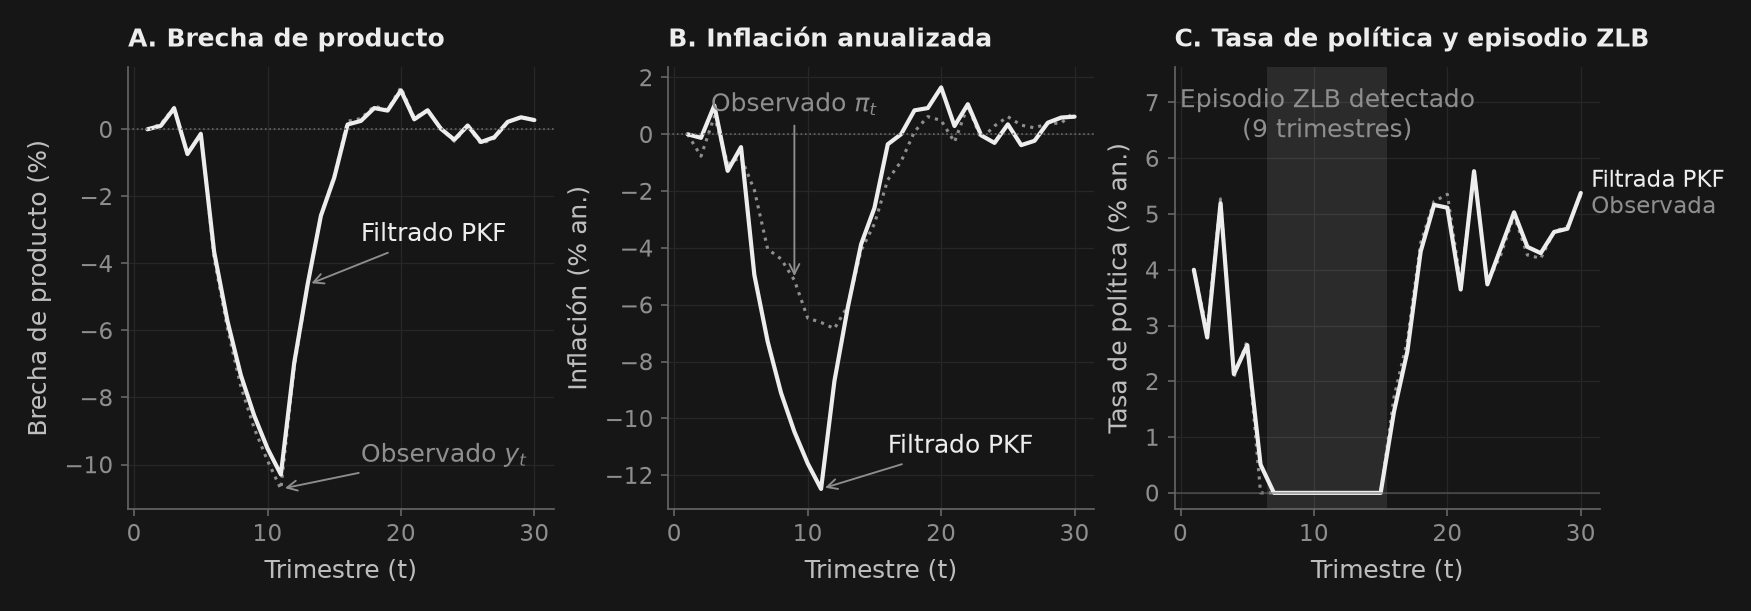

In [8]:
# ==============================================================================
# Simulación 6: Estimación de Estados y Evaluación de Verosimilitud con el Filtro de Kalman Lineal por Partes
# ==============================================================================
from puremacro.dsge.occbin import piecewise_kalman_filter
from puremacro.state_space import kalman_filter
from puremacro.dsge import make_state_space_from_varobs

# Generación de un conjunto de datos macroeconómicos de 30 trimestres con trampa de liquidez
# fundamentado en las dinámicas posteriores a 2008 (tasas ancladas al piso)
rng = np.random.default_rng(42)
T_pkf = 30
dates_pkf = pd.date_range("2008-01-01", periods=T_pkf, freq="QS")

y_sim = np.zeros(T_pkf)
pi_sim = np.zeros(T_pkf)
r_sim = np.zeros(T_pkf)

# Proceso generador estructural con choque contractivo severo entre t=5 y t=10
for t in range(1, T_pkf):
    sg = -0.04 if 5 <= t <= 10 else rng.normal(0, 0.005)
    y_sim[t] = 0.7 * y_sim[t - 1] - (r_sim[t - 1] - 0.5 * pi_sim[t - 1]) + sg
    pi_sim[t] = 0.5 * pi_sim[t - 1] + 0.1 * y_sim[t] + rng.normal(0, 0.002)
    notional_r = 1.5 * pi_sim[t] + 0.125 * y_sim[t]
    r_sim[t] = max(-r_ss, notional_r)

data_pkf = pd.DataFrame({"y": y_sim, "pi": pi_sim, "r": r_sim}, index=dates_pkf)

# Covarianza de error de medición (desviación estándar de 10 puntos base)
H_meas = 1e-4 * np.eye(3)

# 1. Evaluación del Filtro de Kalman Lineal por Partes (PKF)
res_pkf = piecewise_kalman_filter(
    m_unconstrained=ref_model,
    m_constrained_dict={"zlb": cons_model},
    data=data_pkf,
    varobs=["y", "pi", "r"],
    constraints={"zlb": constraint},
    H=H_meas,
    horizon=25,
)

# Desempaquetado del resultado
ll_pkf, filtered_states_pkf, regimes_pkf = res_pkf

# 2. Evaluación del Filtro de Kalman Lineal estándar sobre datos idénticos
ssm = make_state_space_from_varobs(ref_model, varobs=["y", "pi", "r"])
ssm.H = H_meas
out_lin_kalman = kalman_filter(data_pkf.values, ssm)
ll_linear = out_lin_kalman["loglik"]

loglik_gain = res_pkf.log_likelihood - ll_linear
n_binding_pkf = sum(r > 0 for r in res_pkf.regimes)

print("=" * 76)
print("MARCADOR DE ESTIMACIÓN DE ESTADOS CON EL FILTRO DE KALMAN LINEAL POR PARTES")
print("=" * 76)
print(f"Log-Verosimilitud PKF ln L(Y|theta) : {res_pkf.log_likelihood:8.2f}")
print(f"Log-Verosimilitud Kalman Lineal     : {ll_linear:8.2f}")
print(f"Ganancia de Verosimilitud con PKF   : {loglik_gain:+8.2f} puntos log")
print(f"Trimestres en ZLB Detectados        : {n_binding_pkf} de {T_pkf} trimestres")
print(f"Convergencia de Régimen en Filtro   : {res_pkf.converged}")
print("=" * 76)

# Reporte formal estilo publicación
print("\n" + res_pkf.summary())

# Visualización: Estados Filtrados vs Datos Observados y Detección de Regímenes ZLB
fig, axes = _nbstyle.figura(1, 3)
time_pkf = np.arange(1, T_pkf + 1)
reg_arr = np.asarray(res_pkf.regimes)

# Panel 1: Brecha de Producto Filtrada
ax = axes[0]
y_obs = data_pkf["y"] * 100
y_filt = res_pkf.filtered_states["y"] * 100
ax.plot(time_pkf, y_obs, color=_nbstyle.NOTA, linestyle=":", linewidth=1.5)
ax.plot(time_pkf, y_filt, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# Las dos series casi coinciden: cada una se nombra en la recesión, donde el punteado asoma bajo el trazo continuo
i_min = int(np.argmin(y_filt.values))
ax.annotate("Filtrado PKF", xy=(time_pkf[i_min + 2], y_filt.iloc[i_min + 2]), xytext=(time_pkf[i_min + 6], y_filt.iloc[i_min + 2] + 1.5),
            ha="left", va="center", color=_nbstyle.S1["color"], arrowprops=_nbstyle.FLECHA)
ax.annotate("Observado $y_t$", xy=(time_pkf[i_min], y_obs.iloc[i_min]), xytext=(time_pkf[i_min] + 6, y_obs.iloc[i_min] + 1.0),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Trimestre (t)")
ax.set_ylabel("Brecha de producto (%)")
ax.set_title("A. Brecha de producto")

# Panel 2: Inflación Filtrada
ax = axes[1]
pi_obs = data_pkf["pi"] * 400
pi_filt = res_pkf.filtered_states["pi"] * 400
ax.plot(time_pkf, pi_obs, color=_nbstyle.NOTA, linestyle=":", linewidth=1.5)
ax.plot(time_pkf, pi_filt, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# Las dos series se separan en la trampa: cada una se nombra donde más difieren
i_min = int(np.argmin(pi_filt.values))
ax.annotate("Observado $\\pi_t$", xy=(time_pkf[i_min - 2], pi_obs.iloc[i_min - 2]), xytext=(time_pkf[i_min - 2], 0.6),
            ha="center", va="bottom", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.annotate("Filtrado PKF", xy=(time_pkf[i_min], pi_filt.iloc[i_min]), xytext=(time_pkf[i_min] + 5, pi_filt.iloc[i_min] + 1.5),
            ha="left", va="center", color=_nbstyle.S1["color"], arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Trimestre (t)")
ax.set_ylabel("Inflación (% an.)")
ax.set_title("B. Inflación anualizada")

# Panel 3: Tasa de Política y Episodios ZLB Sombreados
ax = axes[2]
r_obs_lev = (r_ss + data_pkf["r"]) * 400
r_filt_lev = (r_ss + res_pkf.filtered_states["r"]) * 400
ax.plot(time_pkf, r_obs_lev, label="Observada", color=_nbstyle.NOTA, linestyle=":", linewidth=1.5)
ax.plot(time_pkf, r_filt_lev, label="Filtrada PKF", **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=0.8, alpha=0.6)

# Resaltar periodos de ZLB detectados
for s_idx in range(len(reg_arr)):
    if reg_arr[s_idx] > 0:
        ax.axvspan(s_idx + 0.5, s_idx + 1.5, color=_nbstyle.RECESION, lw=0)
t_zlb = time_pkf[reg_arr > 0]
# La franja se nombra por encima de las sendas, donde ningún trazo alcanza al texto
r_top_pkf = max(r_obs_lev.max(), r_filt_lev.max())
ax.set_ylim(top=r_top_pkf * 1.32)
ax.annotate(f"Episodio ZLB detectado\n({len(t_zlb)} trimestres)", xy=(t_zlb.mean(), r_top_pkf * 1.17),
            ha="center", va="center", color=_nbstyle.NOTA)

ax.set_xlabel("Trimestre (t)")
ax.set_ylabel("Tasa de política (% an.)")
ax.set_title("C. Tasa de política y episodio ZLB")
_nbstyle.etiquetar(ax, donde="fin")   # las dos series coinciden: sus nombres van fuera, junto al último punto

plt.show()

## 8. Puente al tema 4: RBC con inversión irreversible

El ejemplo de Oi–Hartman–Abel mantiene el salario fijo para aislar la flexibilidad del trabajo. Ahora cerramos el **equilibrio general**: el hogar elige consumo, trabajo y capital, y la inversión instalada no se puede transformar de nuevo en consumo. Queremos saber **cuándo se activa esa restricción y cómo cambia la recuperación**.

Sin crecimiento tendencial, el planificador resuelve
\[
\max E_0\sum_{t=0}^{\infty}\beta^t\left[\frac{c_t^{1-\sigma}}{1-\sigma}+\mu\frac{(1-l_t)^{1-\nu}}{1-\nu}\right],
\]
con el límite logarítmico si $\sigma=1$, sujeto a
\[
y_t=e^{a_t}k_{t-1}^{\alpha}l_t^{1-\alpha},\quad c_t+i_t=y_t,\quad
k_t=(1-\delta)k_{t-1}+i_t,\quad \boxed{i_t\geq0},\qquad
a_t=\rho_a a_{t-1}+\varepsilon_t.
\]
La restricción recae sobre la **inversión bruta**: el capital sí puede disminuir por depreciación. Partimos del estado estacionario determinista, donde $\bar i=\delta\bar k>0$ y la restricción está inactiva. El parámetro $\mu$ se calibra para $\bar l=0.33$.

### Kuhn–Tucker: por qué aparece el multiplicador futuro

Sustituyendo $i_t=k_t-(1-\delta)k_{t-1}$, sean $\lambda_t$ el multiplicador de recursos y $\eta_t\geq0$ el de irreversibilidad. El sumando del lagrangiano es
\[
u(c_t,l_t)+\lambda_t\left[y_t+(1-\delta)k_{t-1}-c_t-k_t\right]
+\eta_t\left[k_t-(1-\delta)k_{t-1}\right].
\]
Las condiciones de consumo, trabajo y capital son
\[
\lambda_t=c_t^{-\sigma},\qquad
\mu(1-l_t)^{-\nu}=\lambda_t(1-\alpha)\frac{y_t}{l_t},
\]
\[
\boxed{\lambda_t-\eta_t=\beta E_t\left[\lambda_{t+1}
\left(\alpha\frac{y_{t+1}}{k_t}+1-\delta\right)-(1-\delta)\eta_{t+1}\right]},
\qquad i_t\geq0,\quad\eta_t\geq0,\quad\eta_t i_t=0.
\]
**No basta con añadir un multiplicador a la Euler habitual y omitir el del periodo siguiente.** Aumentar $k_t$ eleva el capital que debe conservarse mañana; de ahí el término $-(1-\delta)\eta_{t+1}$.

Para interpretarlo, definimos $\xi_t=\eta_t/\lambda_t$, $q_t^K=1-\xi_t$ y $M_{t,t+1}=\beta\lambda_{t+1}/\lambda_t$:
\[
q_t^K=E_t\left[M_{t,t+1}\left(\alpha\frac{y_{t+1}}{k_t}+(1-\delta)q_{t+1}^K\right)\right],
\qquad q_t^K\leq1,\quad i_t\geq0,\quad(1-q_t^K)i_t=0.
\]
Si $i_t>0$, el valor marginal del capital iguala su costo de reposición: $q_t^K=1$. Si $q_t^K<1$, querríamos vender capital, pero la restricción obliga a $i_t=0$. $q^K$ es un valor sombra; no es el choque a la eficiencia de la inversión del tema 4.

El bloque productivo sigue permitiendo ajustar el trabajo tras observar $A_t=e^{a_t}$. A salario fijo, el beneficio operativo sería $B(w_t)k_{t-1}A_t^{1/\alpha}$, como en las láminas. Aquí $w_t$, $c_t$ y el descuento $M_{t,t+1}$ se determinan conjuntamente: aquella convexidad identifica un incentivo parcial, no el signo de la inversión agregada.

Referencia metodológica: [Guerrieri e Iacoviello (2015)](https://www.matteoiacoviello.com/research_files/JME_2015.pdf), que también estudian un RBC con un piso a la inversión. Esta aplicación mantiene trabajo endógeno y usa el piso de irreversibilidad completa $i_t\geq0$; no reproduce su calibración.

### 8.1. Los dos regímenes que recibe OccBin

Para $x\in\{y,c,k,l\}$ usamos desviaciones proporcionales **en niveles**, $\hat x_t=(x_t-\bar x)/\bar x$. Para inversión usamos
\[
j_t\equiv\frac{i_t-\bar i}{\bar k},\qquad i_t\geq0\iff j_t\geq-\delta.
\]
No tomamos $\log i_t$: no existe cuando $i_t=0$. En el código `y,c,k,l` representan las desviaciones con sombrero; `a` es log-PTF y `xi` la aproximación de primer orden a $\eta_t/\lambda_t$.

Sea $\bar r=1/\beta-1+\delta=\alpha\bar y/\bar k$. Las ecuaciones comunes a ambos regímenes son
\[
\begin{aligned}
a_t&=\rho_a a_{t-1}+\varepsilon_t,\\
\hat y_t&=a_t+\alpha\hat k_{t-1}+(1-\alpha)\hat l_t,\\
\sigma\hat c_t+\left(1+\nu\frac{\bar l}{1-\bar l}\right)\hat l_t&=\hat y_t,\\
\frac{\bar y}{\bar k}\hat y_t&=\frac{\bar c}{\bar k}\hat c_t+j_t,\\
\hat k_t&=(1-\delta)\hat k_{t-1}+j_t,\\
\sigma(E_t\hat c_{t+1}-\hat c_t)-\xi_t+\beta(1-\delta)E_t\xi_{t+1}
-\beta\bar r(E_t\hat y_{t+1}-\hat k_t)&=0.
\end{aligned}
\]
La séptima ecuación es **$\xi_t=0$** en el régimen libre y **$j_t=-\delta$** en el restringido. Se activa el piso si el régimen libre propone $j_t<-\delta$; se abandona si el régimen restringido produce $\xi_t<0$. Por eso declaramos explícitamente `relax_variable="xi"`: comparar la inversión ya fijada al piso no comprueba el signo del multiplicador.

Ambos sistemas se aproximan alrededor del **mismo** estado estacionario libre. El régimen restringido conserva la constante $\delta$ y no se resuelve como un estado estacionario alternativo.

In [9]:
rbc_labels = {'sweep_columns': ['Innovación log-PTF',
                   'Cambio PTF (%)',
                   'i₀/ȳ lineal (%)',
                   'i₀/ȳ OccBin (%)',
                   'Periodos i=0 (OccBin)'],
 'nonlinear': 'No lineal',
 'linear': 'Lineal libre',
 'comparison_columns': ['Innovación log-PTF',
                        'Método',
                        'Periodos i=0',
                        'c₀: desv. (%)',
                        'y₀: desv. (%)',
                        'Máximo ξ'],
 'nonlinear_error': 'Máximo residuo no lineal:',
 'investment_axis': 'Inversión bruta (% de ȳ)',
 'consumption_axis': 'Consumo: desv. de EE (%)',
 'time_axis': 'Trimestres tras el choque',
 'audit_ok': 'RBC: factibilidad, complementariedad, Euler, horizonte y equivalencia lineal '
             'verificados.',
 'terminal_error': 'Cambio máximo al duplicar horizonte (primeros 40 periodos):'}

# RBC: the seven equations above, with one switching equation.
from puremacro.dsge import build_dynare, solve_occbin, OccBinConstraint

rbc_p = dict(alpha=0.33, beta=0.99, delta=0.025, sigma=1.0,
             nu=1.5, lbar=0.33, rho=0.95)
rbc_p["rbar"] = 1 / rbc_p["beta"] - 1 + rbc_p["delta"]
rbc_p["yk"] = rbc_p["rbar"] / rbc_p["alpha"]
rbc_p["ck"] = rbc_p["yk"] - rbc_p["delta"]
rbc_p["lab"] = 1 + rbc_p["nu"] * rbc_p["lbar"] / (1 - rbc_p["lbar"])
rbc_kbar = rbc_p["lbar"] * (rbc_p["alpha"] / rbc_p["rbar"])**(1 / (1-rbc_p["alpha"]))
rbc_cbar = rbc_p["ck"] * rbc_kbar
rbc_mu = ((1-rbc_p["alpha"]) * rbc_p["yk"] * rbc_kbar / rbc_p["lbar"]
          * rbc_cbar**(-rbc_p["sigma"]) * (1-rbc_p["lbar"])**rbc_p["nu"])
rbc_vars = ["a", "k", "c", "l", "y", "j", "xi"]

def rbc_equations(lead, curr, lag, shocks, p):
    return [curr.a - p.rho * lag.a - shocks.e_a,
            curr.y - curr.a - p.alpha * lag.k - (1-p.alpha) * curr.l,
            p.sigma * curr.c + p.lab * curr.l - curr.y,
            p.yk * curr.y - p.ck * curr.c - curr.j,
            curr.k - (1-p.delta) * lag.k - curr.j,
            p.sigma * (lead.c-curr.c) - curr.xi + p.beta * (1-p.delta) * lead.xi
            - p.beta * p.rbar * (lead.y-curr.k),
            curr.xi]

def rbc_binding_equations(lead, curr, lag, shocks, p):
    residuals = rbc_equations(lead, curr, lag, shocks, p)
    residuals[-1] = curr.j + p.delta
    return residuals

def make_rbc_models(p, innovation_sd=0.007):
    args = dict(variables=rbc_vars, shocks=["e_a"], params=p,
                steady_state={v: 0.0 for v in rbc_vars},
                shock_cov=np.array([[innovation_sd**2]]))
    ref = build_dynare(rbc_equations, **args)
    # Common expansion point: it deliberately does not satisfy j = -delta.
    binding = build_dynare(rbc_binding_equations, **args,
                          check_steady_state=False, strict=False)
    constraint = OccBinConstraint(variable="j", threshold=-p["delta"], operator="<",
                                  relax_variable="xi", relax_threshold=0.0,
                                  relax_operator="<")
    return ref, binding, constraint

rbc_ref, rbc_bind, rbc_constraint = make_rbc_models(rbc_p)
rbc_H, rbc_stress = 160, -0.30  # Deliberately large stress; log TFP units.
rbc_dr = rbc_ref.decision_rules()
rbc_P = np.zeros((len(rbc_vars), len(rbc_vars)))
for state in rbc_ref.states:
    rbc_P[:, rbc_vars.index(state)] = rbc_dr.ghx[state].to_numpy()

def rbc_linear_path(innovation, H=rbc_H):
    path = np.zeros((H, len(rbc_vars)))
    path[0] = rbc_dr.ghu.to_numpy()[:, 0] * innovation
    for t in range(1, H):
        path[t] = rbc_P @ path[t-1]
    return pd.DataFrame(path, columns=rbc_vars)

def rbc_occbin_path(innovation, H=rbc_H):
    result = solve_occbin(rbc_ref, rbc_bind, rbc_constraint,
                         shock_sequence=np.array([innovation]), horizon=H, max_iter=100)
    assert result.converged, "RBC regime iteration or terminal condition failed"
    return result

rbc_occ = rbc_occbin_path(rbc_stress)
rbc_linear = rbc_linear_path(rbc_stress)
print(pd.Series({**rbc_p, "kbar": rbc_kbar, "cbar": rbc_cbar, "mu": rbc_mu}).round(6))

alpha    0.330000
beta     0.990000
delta    0.025000
sigma    1.000000
nu       1.500000
lbar     0.330000
rho      0.950000
rbar     0.035101
yk       0.106367
ck       0.081367
lab      1.738806
kbar     9.354978
cbar     0.761184
mu       1.455567
dtype: float64


### 8.2. Un choque realizado y un ejercicio de estrés

La innovación llega por sorpresa en $t=0$; desde entonces se prevén innovaciones futuras iguales a cero y $a_t=\rho_a^t\varepsilon_0$. Esta es una **senda condicional de previsión perfecta**, no una GIRF integrada sobre futuros choques.

**Predigan:** con $\bar i=\delta\bar k>0$, ¿un choque habitual de 0.7% debe activar necesariamente $i_t=0$? ¿Qué variable permitirá comprobar que resulta óptimo salir del régimen restringido?

La tabla barre tamaños del choque, conservando la calibración. El caso de estrés usa $\varepsilon_0=-0.30$ en log-PTF: equivale a una caída de $100(e^{-0.30}-1)\simeq-25.9\%$ en niveles. Es deliberadamente extremo, no una fluctuación típica ni una calibración del efecto de la incertidumbre. Una caída de 30 puntos logarítmicos exige comprobar la precisión de la aproximación local.

In [10]:
rbc_sweep_rows = []
for innovation in [-0.007, -0.05, -0.10, -0.20, -0.25, rbc_stress]:
    result = rbc_occbin_path(innovation)
    linear = rbc_linear_path(innovation)
    rbc_sweep_rows.append([innovation, 100*np.expm1(innovation),
                          100*(rbc_p["delta"]+linear["j"].iloc[0])/rbc_p["yk"],
                          100*(rbc_p["delta"]+result["j"].iloc[0])/rbc_p["yk"],
                          result.binding_periods])
rbc_sweep = pd.DataFrame(rbc_sweep_rows, columns=rbc_labels["sweep_columns"])
display(rbc_sweep.round(4))

,Innovación log-PTF,Cambio PTF (%),i₀/ȳ lineal (%),i₀/ȳ OccBin (%),Periodos i=0 (OccBin)
0,-0.007,-0.6976,22.7539,22.7539,0
1,-0.050,-4.8771,18.1484,18.1484,0
2,-0.100,-9.5163,12.7931,12.7931,0
3,-0.200,-18.1269,2.0827,2.0827,0
4,-0.250,-22.1199,-3.2725,0.0000,2
5,-0.300,-25.9182,-8.6278,0.0000,5


### 8.3. Comprobar la aproximación: las mismas condiciones sin linealizarlas

OccBin resuelve las ecuaciones por tramos, pero sus coeficientes provienen de aproximaciones de primer orden. **Convergencia del algoritmo no significa precisión de la aproximación económica.**

El siguiente comparador resuelve las condiciones no lineales de previsión perfecta y la complementariedad mediante
\[
\sqrt{(j_t+\delta)^2+\xi_t^2}-(j_t+\delta)-\xi_t=0.
\]
Esta igualdad equivale a $j_t+\delta\geq0$, $\xi_t\geq0$ y $(j_t+\delta)\xi_t=0$. La senda inicial es la de OccBin. Al final del horizonte usamos la regla estable del régimen libre como cierre local; duplicamos el horizonte para comprobar que ese cierre no mueve los primeros 40 periodos. **Este comparador tampoco integra riesgo futuro.**

La tabla incluye el choque de $-0.25$: cerca de la frontera, los dos métodos pueden discrepar incluso sobre si la restricción llega a activarse. No imponemos que ambos produzcan el mismo número de periodos restringidos.

In [11]:
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix

# These are the nonlinear FOCs, written in proportional level deviations.
def rbc_exact_residuals(X, innovation, p=rbc_p):
    H = len(X)
    lag = np.vstack([np.zeros(len(rbc_vars)), X[:-1]])
    lead = np.vstack([X[1:], rbc_P @ X[-1]])
    a, k, c, l, y, j, xi = X.T
    eps = np.zeros(H)
    eps[0] = innovation
    M = p["beta"] * ((1+lead[:, 2])/(1+c))**(-p["sigma"])
    return np.column_stack([
        a-p["rho"]*lag[:, 0]-eps,
        (1+y)-np.exp(a)*(1+lag[:, 1])**p["alpha"]*(1+l)**(1-p["alpha"]),
        (1+c)**p["sigma"]*((1-p["lbar"]*(1+l))/(1-p["lbar"]))**(-p["nu"])
        -(1+y)/(1+l),
        p["yk"]*y-p["ck"]*c-j,
        k-(1-p["delta"])*lag[:, 1]-j,
        1-xi-M*(p["rbar"]*(1+lead[:, 4])/(1+k)+(1-p["delta"])*(1-lead[:, 6])),
        np.hypot(j+p["delta"], xi)-(j+p["delta"])-xi,
    ])

def rbc_nonlinear_path(innovation, H=rbc_H):
    start = rbc_occbin_path(innovation, H).simulated_path.to_numpy()
    n = len(rbc_vars)
    pattern = lil_matrix((n*H, n*H))
    for t in range(H):
        pattern[n*t:n*(t+1), n*max(0, t-1):n*min(H, t+2)] = 1
    # Keep consumption, capital, output and hours positive, and hours below one.
    lower = np.tile([-3, -.95, -.95, -.95, -.95, -np.inf, -np.inf], H)
    upper = np.tile([3, np.inf, np.inf, 1/rbc_p["lbar"]-1-.01,
                     np.inf, np.inf, np.inf], H)
    fit = least_squares(lambda x: rbc_exact_residuals(x.reshape(H, n), innovation).ravel(),
                        start.ravel(), bounds=(lower, upper), jac_sparsity=pattern.tocsr(),
                        xtol=1e-11, ftol=1e-11, gtol=1e-11, max_nfev=500)
    X = fit.x.reshape(H, n)
    error = np.max(np.abs(rbc_exact_residuals(X, innovation)))
    assert fit.success and error < 1e-8, (fit.message, error)
    return pd.DataFrame(X, columns=rbc_vars), error

rbc_nl, rbc_nl_error = rbc_nonlinear_path(rbc_stress)
rbc_nl_edge, rbc_edge_error = rbc_nonlinear_path(-0.25)
rbc_comparison_rows = []
for innovation, nonlinear in [(-0.25, rbc_nl_edge), (rbc_stress, rbc_nl)]:
    occ = rbc_occbin_path(innovation)
    for method, path, periods in [
        ("OccBin", occ.simulated_path, occ.binding_periods),
        (rbc_labels["nonlinear"], nonlinear, int((nonlinear["xi"] > 1e-7).sum()))]:
        rbc_comparison_rows.append([innovation, method, periods, 100*path["c"].iloc[0],
                                   100*path["y"].iloc[0], path["xi"].max()])
rbc_comparison = pd.DataFrame(rbc_comparison_rows, columns=rbc_labels["comparison_columns"])
display(rbc_comparison.round(4))
print(rbc_labels["nonlinear_error"], f"{max(rbc_nl_error, rbc_edge_error):.2e}")

Máximo residuo no lineal: 3.88e-13


,Innovación log-PTF,Método,Periodos i=0,c₀: desv. (%),y₀: desv. (%),Máximo ξ
0,-0.25,OccBin,2,-12.3349,-32.9393,0.0258
1,-0.25,No lineal,0,-9.1226,-29.8374,0.0000
2,-0.30,OccBin,5,-18.1792,-37.4101,0.0697
3,-0.30,No lineal,2,-13.0922,-33.5187,0.0285


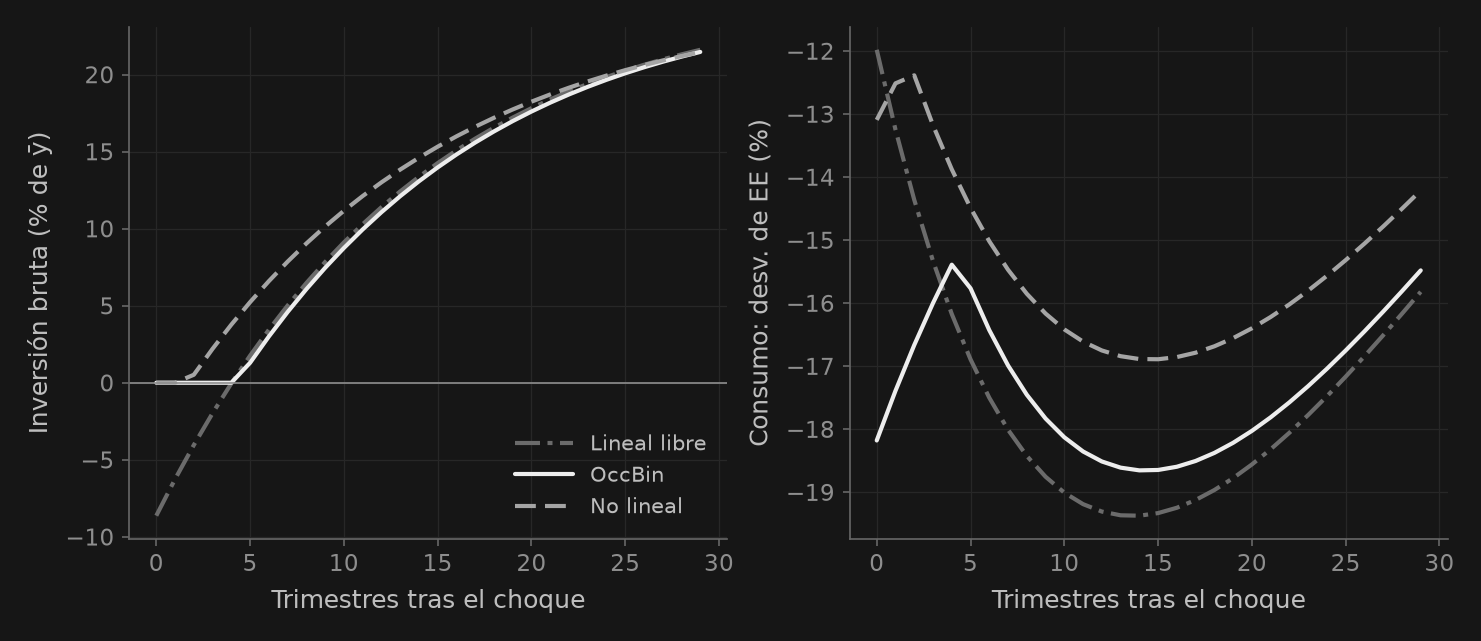

In [12]:
# A fixed-size technology shock; all curves start from the same steady state.
fig, axes = _nbstyle.figura(1, 2, figsize=(plt.rcParams["figure.figsize"]
                               if _nbstyle.PERFIL == "lamina" else None))
rbc_show = 30
rbc_t = np.arange(rbc_show)
rbc_paths = [(rbc_linear, rbc_labels["linear"], _nbstyle.S3),
             (rbc_occ.simulated_path, "OccBin", _nbstyle.S1),
             (rbc_nl, rbc_labels["nonlinear"], _nbstyle.S2)]
for path, label, style in rbc_paths:
    axes[0].plot(rbc_t, 100*(rbc_p["delta"]+path["j"].iloc[:rbc_show])/rbc_p["yk"],
                 label=label, **style)
    axes[1].plot(rbc_t, 100*path["c"].iloc[:rbc_show], label=label, **style)
axes[0].axhline(0, color=_nbstyle.NOTA, lw=.8)
axes[0].set_ylabel(rbc_labels["investment_axis"])
axes[1].set_ylabel(rbc_labels["consumption_axis"])
for ax in axes:
    ax.set_xlabel(rbc_labels["time_axis"])
axes[0].legend(frameon=False, fontsize="small", loc="lower right")
plt.show()

### 8.4. Qué enseña este RBC sobre Oi–Hartman–Abel y la incertidumbre

1. **La irreversibilidad cambia la transmisión de un choque realizado.** Cuando se alcanza el piso, la caída de la inversión se detiene en cero, el capital queda instalado y consumo y trabajo se reajustan. Esto no implica que todo choque negativo se amplifique en todas las variables.
2. **OccBin no calcula el canal de Jensen ni la opción de esperar por riesgo aún no realizado.** En cada régimen usa una aproximación de primer orden y, en estas sendas, impone innovaciones futuras nulas. Cambiar la covarianza de las innovaciones sin cambiar el impulso realizado deja inalterada la senda; agrandar el impulso sí la cambia, pero eso es otro experimento.
3. **Un choque puro a la volatilidad exige resolver las expectativas no lineales.** La sección 9 incorpora la volatilidad como estado y resuelve el Bellman estocástico con puremacro, respetando $i\geq0$. Una perturbación suave de tercer orden, por sí sola, no resuelve la frontera de irreversibilidad.

**Interpretación de la calibración:** el piso de inversión bruta cero está lejos del estado estacionario. Si solo se activa ante caídas extremas de PTF, la irreversibilidad agregada de este RBC es insuficiente para explicar inacción frecuente. La heterogeneidad empresarial o la irreversibilidad parcial son extensiones que deben modelarse explícitamente, no razones para reinterpretar este experimento como un choque de incertidumbre.

**Ejercicios:**
- Baja $\delta$ de 0.025 a 0.01, reconstruye los modelos y repite el barrido y el comparador no lineal. ¿Se acerca el piso al estado estacionario?
- Cambia $\rho_a$ y distingue la persistencia del choque de la duración del régimen restringido.
- Explica por qué $q_t^K<1$ implica inacción y por qué $i_t=0$ permite que $k_t<k_{t-1}$.
- ¿Puede una senda idéntica al duplicar la desviación estándar demostrar que la incertidumbre no importa económicamente? Identifica qué aproximación elimina ese canal.

La auditoría siguiente comprueba factibilidad, multiplicadores, complementariedad, ecuaciones, el cierre terminal y la recuperación del modelo lineal cuando la restricción está inactiva.

In [13]:
# Feasibility, complementarity, and the common resource/capital equations.
for path in [rbc_occ.simulated_path, rbc_nl]:
    investment = rbc_p["delta"] + path["j"].to_numpy()
    xi = path["xi"].to_numpy()
    assert investment.min() > -1e-8 and xi.min() > -1e-8
    assert np.max(np.abs(investment*xi)) < 1e-8
    np.testing.assert_allclose(rbc_p["yk"]*path["y"]-rbc_p["ck"]*path["c"], path["j"], atol=1e-8)
    lag_k = np.r_[0, path["k"].to_numpy()[:-1]]
    np.testing.assert_allclose(path["k"], (1-rbc_p["delta"])*lag_k+path["j"], atol=1e-8)
    assert (1+path[["k", "c", "y", "l"]]).to_numpy().min() > 0
    assert (rbc_p["lbar"]*(1+path["l"])).max() < 1

for innovation in [-0.007, 0.007]:
    small = rbc_occbin_path(innovation)
    assert small.binding_periods == 0
    np.testing.assert_allclose(small.simulated_path, rbc_linear_path(innovation), atol=1e-10)
assert rbc_occ.regimes[-1] == 0 and rbc_occ.binding_periods > 0

# Independent check: the nonlinear FOCs linearize to the equations supplied to OccBin.
from types import SimpleNamespace
rbc_direction = np.random.default_rng(724).normal(size=(5, len(rbc_vars)))
rbc_direction[:, -1] = 0  # Slack complementarity: both systems impose xi=0.
rbc_h = 1e-5
rbc_fd = (rbc_exact_residuals(rbc_h*rbc_direction, 0)
          - rbc_exact_residuals(-rbc_h*rbc_direction, 0))/(2*rbc_h)
rbc_step = lambda row: SimpleNamespace(**dict(zip(rbc_vars, row)))
rbc_lag = np.vstack([np.zeros(len(rbc_vars)), rbc_direction[:-1]])
rbc_lead = np.vstack([rbc_direction[1:], rbc_P@rbc_direction[-1]])
for t in range(len(rbc_direction)):
    local = rbc_equations(rbc_step(rbc_lead[t]), rbc_step(rbc_direction[t]),
                          rbc_step(rbc_lag[t]), SimpleNamespace(e_a=0), SimpleNamespace(**rbc_p))
    # The exact q Euler residual has the same sign as our linear Euler residual.
    np.testing.assert_allclose(rbc_fd[t, :6], local[:6], atol=2e-8, rtol=2e-7)
# Check the future multiplier coefficient explicitly, without imposing xi=0.
rbc_future_xi = np.zeros((3, len(rbc_vars)))
rbc_future_xi[1, -1] = 1
rbc_dxi = (rbc_exact_residuals(rbc_h*rbc_future_xi, 0)
           - rbc_exact_residuals(-rbc_h*rbc_future_xi, 0))/(2*rbc_h)
np.testing.assert_allclose(rbc_dxi[0, 5], rbc_p["beta"]*(1-rbc_p["delta"]), atol=1e-9)

# Terminal-horizon check for both solvers, on the first 40 quarters.
rbc_occ_long = rbc_occbin_path(rbc_stress, 2*rbc_H)
rbc_nl_long, _ = rbc_nonlinear_path(rbc_stress, 2*rbc_H)
rbc_terminal_difference = np.max(np.abs(rbc_nl_long.iloc[:40].to_numpy()-rbc_nl.iloc[:40].to_numpy()))
np.testing.assert_allclose(rbc_occ_long.simulated_path.iloc[:40], rbc_occ.simulated_path.iloc[:40], atol=1e-10)
assert rbc_terminal_difference < 1e-5, rbc_terminal_difference

# Doubling innovation SD at a FIXED realized impulse does not change first-order policies.
rbc_ref_risk, rbc_bind_risk, rbc_con_risk = make_rbc_models(rbc_p, innovation_sd=0.014)
rbc_covariance_check = solve_occbin(rbc_ref_risk, rbc_bind_risk, rbc_con_risk,
                                   shock_sequence=np.array([rbc_stress]), horizon=rbc_H, max_iter=100)
assert rbc_covariance_check.converged
np.testing.assert_allclose(rbc_covariance_check.simulated_path, rbc_occ.simulated_path, atol=1e-12)
print(rbc_labels["audit_ok"])
print(rbc_labels["terminal_error"], f"{rbc_terminal_difference:.2e}")

RBC: factibilidad, complementariedad, Euler, horizonte y equivalencia lineal verificados.
Cambio máximo al duplicar horizonte (primeros 40 periodos): 1.83e-10


## 9. Un choque de incertidumbre: RBC irreversible con volatilidad estocástica

La sección 8 cambia la **productividad realizada**. Ahora preguntamos: **si hoy no cambian las máquinas ni la productividad, pero mañana hay más riesgo, ¿cambian hoy consumo e inversión?** Conservamos preferencias, tecnología, trabajo endógeno, equilibrio general e irreversibilidad. Sustituimos el proceso exógeno y el método de solución.

Sean $k=k_{t-1}$ el capital disponible y $v_t=\log s_t$ la log-desviación estándar de la próxima innovación de productividad. El proceso es
\[
a_{t+1}=\rho_a a_t-\frac12 e^{2v_t}+e^{v_t}\epsilon_{t+1},\qquad
v_{t+1}=(1-\rho_v)\bar v+\rho_v v_t+\tau_v u_{t+1},
\]
con $\epsilon,u$ normales estándar, independientes entre sí y en el tiempo. Observamos $(k,a_t,v_t)$ **antes** de elegir $(c_t,l_t,k_t)$. El término $-e^{2v_t}/2$ garantiza
\[
E_t[A_{t+1}]=e^{\rho_a a_t},\qquad
\operatorname{Var}_t(A_{t+1})=e^{2\rho_a a_t}\left(e^{e^{2v_t}}-1\right),\quad A=e^a.
\]
Así, variar $v_t$ conserva la **media condicional a un periodo en niveles**, no solo la media del logaritmo. No imponemos igualdad de medias incondicionales ni de todas las medias a horizontes posteriores.

**Experimento:** a igual $k=\bar k$ y $a_0$, comparamos $v_0=\bar v$ con $v_0=\bar v+\log2$. La desviación estándar se duplica de 0.02 a 0.04 y la varianza se cuadruplica. Usamos $\rho_v=0.8$ y $\tau_v=0.15$; el salto es de $\log2/0.15\simeq4.62$ desviaciones estándar de la innovación de log-volatilidad. Es una calibración didáctica, no estimada; el tamaño no se interpreta como un choque habitual. La mediana de volatilidad 0.02 sustituye el 0.007 de la sección 8.

Un GARCH convencional permite varianza cambiante, pero la actualiza a partir de innovaciones realizadas al cuadrado. La volatilidad estocástica tiene un choque propio: podemos aumentar el riesgo sin introducir una caída contemporánea de productividad. Véase [Shin y Zhong (2016), p. 6](https://www.federalreserve.gov/econresdata/feds/2016/files/2016040pap.pdf).

**Predigan antes de ejecutar:** ¿puede subir la inversión agregada aunque aumente la probabilidad de que mañana algunas realizaciones obliguen a invertir cero? El signo se determinará en equilibrio general.

In [14]:
sv_labels = {'moments': ['DE innovación log-PTF', 'E[A₁ | a₀=0]', 'Var[A₁ | a₀=0]'], 'meshes': ['Inicial', 'Refinada'], 'diagnostics': ['Malla', 'Iteraciones', 'Residuo de Bellman', 'Máx. residuo Euler relativo', 'Estados con i=0', 'Segundos'], 'impact_columns': ['Malla', 'a₀', 'Δc₀/ c̄ (pp)', 'Δi₀/ ȳ (pp)', 'Δy₀/ ȳ (pp)', 'Δl₀/ l̄ (pp)'], 'refinement': 'Máximo cambio de la respuesta al refinar (pp):', 'girf_columns': ['a₀', 'h', 'Δc/ c̄ (pp)', 'Error MC: c', 'Δi/ ȳ (pp)', 'Error MC: i'], 'binding_columns': ['a₀', 'h', 'P₀ (%)', 'P₁ (%)', 'ΔP (pp)', 'Error MC (pp)'], 'initial_states': ['a₀ = 0', 'a₀ = −0.25'], 'c_axis': 'Consumo: diferencia (% de c̄)', 'i_axis': 'Inversión: diferencia (% de ȳ)', 'time_axis': 'Trimestres tras el choque de volatilidad'}

sv_params = dict(rbc_p, mu=rbc_mu, rho_v=.8, tau_v=.15, vbar=np.log(.02))
sv_ybar = rbc_p["yk"]*rbc_kbar
sv_jump = np.log(2)
# Check the conditional mean in levels, integrating the lognormal distribution.
sv_z, sv_w = np.polynomial.hermite.hermgauss(9)
sv_z, sv_w = np.sqrt(2)*sv_z, sv_w/np.sqrt(np.pi)
sv_moments = []
for sd in [.02, .04]:
    future_A = np.exp(-.5*sd**2 + sd*sv_z)  # a_0=0 in both cases
    mean_A = sv_w @ future_A
    variance_A = sv_w @ (future_A-mean_A)**2
    np.testing.assert_allclose(mean_A, 1., atol=1e-13)
    np.testing.assert_allclose(variance_A, np.expm1(sd**2), rtol=1e-10)
    sv_moments.append([sd, mean_A, variance_A])
display(pd.DataFrame(sv_moments, columns=sv_labels["moments"]).round(8))

,DE innovación log-PTF,E[A₁ | a₀=0],Var[A₁ | a₀=0]
0,0.02,1.0,0.000400
1,0.04,1.0,0.001601


### 9.1. Resolver el Bellman con puremacro

Resolvemos el mismo problema estocástico:
\[
V(k,a,v)=\max_{c,l,k'}\{u(c,l)+\beta E[V(k',a',v')\mid a,v]\},
\quad c+k'=e^ak^\alpha l^{1-\alpha}+(1-\delta)k,\quad k'\geq(1-\delta)k.
\]
El motor es **`puremacro.vfi.Case2Problem(...).solve()`**, disponible en puremacro 5.3.0. Ejecuta iteración de valor con pasos de Howard. El cuaderno proporciona preferencias, transición, retornos y restricciones; **la iteración dinámica la realiza puremacro**.

Construimos una cadena conjunta $z=(a,v)$ mediante cuadratura Gauss–Hermite e interpolación. No suponemos que la transición de productividad sea independiente de la volatilidad. Para cada elección de capital calculamos el óptimo estático de trabajo, usando
\[
c(l;k,a)=\left[\frac{(1-\alpha)e^ak^\alpha}{\mu}\,l^{-\alpha}(1-l)^\nu\right]^{1/\sigma}.
\]
En la API, `a_grid` es la malla de **capital**, `z_grid` enumera los pares $(a,v)$ y `P_z` contiene sus probabilidades conjuntas. `d_grid` enumera decisiones y `aprime_fn` devuelve el índice de capital resultante. Una elección con inversión negativa recibe retorno $-\infty$.

Usamos una malla geométrica con paso $h=-\log(1-\delta)/M$: el piso $k'=(1-\delta)k$ corresponde exactamente a retroceder $M$ nodos, salvo en el borde inferior del dominio. Una malla semilla ($M=8$) incluye todos los capitales futuros factibles por recursos. Las mallas posteriores buscan alrededor de la política anterior e incluyen explícitamente inversión cero. Comprobamos que la búsqueda refinada no termine en un extremo interior y contrastamos estados seleccionados con **todos** los capitales futuros de la malla.

**De la solución discreta a las gráficas.** Las respuestas de incertidumbre son pequeñas: saltar un nodo de capital puede ocultarlas. Diferenciamos localmente la función de valor de puremacro con un polinomio cúbico (Savitzky–Golay, 15 nodos), $m=V_k=k^{-1}V_{\log k}$, e interpolamos $\beta E[m]$. Para evaluar una política continua resolvemos una sola decisión estática/Euler:
\[
\lambda-\eta=\beta E[m(k',a',v')],\qquad
m=\lambda\alpha y/k+(1-\delta)(\lambda-\eta).
\]
Si en $i=0$ se cumple $\lambda\geq\beta E[m']$, mantenemos ese piso; de lo contrario buscamos $\lambda=\beta E[m']$. **No volvemos a iterar una política propia**. Esta recuperación continua es una aproximación adicional, que verificamos con Euler independiente y sensibilidad al suavizado. La envolvente conserva el multiplicador futuro: no lo eliminamos de la auditoría.

La malla es finita y extendemos marginales constantemente fuera de sus bordes al evaluar colas. La tolerancia de Bellman no mide el error de discretización: verificamos también refinamiento, complementariedad, residuos fuera de nodos, dominio y simulaciones. Convergencia numérica no significa solución estocástica exacta.


In [15]:
from scipy.sparse import coo_matrix
from scipy.interpolate import RegularGridInterpolator
from numpy.polynomial.hermite import hermgauss
from time import perf_counter


def sv_weights(grid, x):
    """Linear interpolation; constant extension at the finite grid boundary."""
    index = np.clip(np.searchsorted(grid, x)-1, 0, len(grid)-2)
    weight = np.clip((x-grid[index])/(grid[index+1]-grid[index]), 0, 1)
    return index, weight


def sv_transition(ag, vg, p, nq):
    """Sparse quadrature/interpolation operator for (a', v') given (a, v)."""
    nodes, weights = hermgauss(nq)
    nodes, weights = np.sqrt(2)*nodes, weights/np.sqrt(np.pi)
    a, v = np.meshgrid(ag, vg, indexing="ij")
    a, v = a.ravel()[:, None, None], v.ravel()[:, None, None]
    ap = p["rho"]*a - .5*np.exp(2*v) + np.exp(v)*nodes[None, :, None]
    vp = (1-p["rho_v"])*p["vbar"] + p["rho_v"]*v + p["tau_v"]*nodes[None, None, :]
    ap, vp = np.broadcast_arrays(ap, vp)
    ia, wa = sv_weights(ag, ap)
    iv, wv = sv_weights(vg, vp)
    probability = np.broadcast_to(weights[None, :, None]*weights[None, None, :], ap.shape)
    row = np.broadcast_to(np.arange(len(ag)*len(vg))[:, None, None], ap.shape)
    rows, columns, values = [], [], []
    for da in (0, 1):
        for dv in (0, 1):
            rows.append(row.ravel())
            columns.append(((ia+da)*len(vg)+iv+dv).ravel())
            values.append((probability*(wa if da else 1-wa)*(wv if dv else 1-wv)).ravel())
    size = len(ag)*len(vg)
    return coo_matrix((np.concatenate(values), (np.concatenate(rows), np.concatenate(columns))),
                      shape=(size, size)).tocsr()


def sv_allocation(labor, capital, log_tfp, p):
    """Intratemporal FOC gives c(l); resources then give k'(l)."""
    output = np.exp(log_tfp)*capital**p["alpha"]*labor**(1-p["alpha"])
    consumption = ((1-p["alpha"])*output/labor*(1-labor)**p["nu"]/p["mu"])**(1/p["sigma"])
    next_capital = output + (1-p["delta"])*capital - consumption
    return consumption, output, next_capital


def sv_floor_labor(k, a, p):
    """Find labor at i=0, without taking logarithms of investment."""
    lower, upper = np.full_like(k, 1e-6), np.full_like(k, 1-1e-6)
    for _ in range(45):
        mid = (lower+upper)/2
        _, _, kp = sv_allocation(mid, k, a, p)
        below = kp < (1-p["delta"])*k
        lower, upper = np.where(below, mid, lower), np.where(below, upper, mid)
    return (lower+upper)/2


from puremacro.vfi import Case2Problem
from scipy.signal import savgol_filter

def sv_static_given_i(k,a,investment,p):
    """Static labor optimum conditional on investment; safeguarded Newton."""
    k,a,investment=np.broadcast_arrays(k,a,investment)
    lower=np.full_like(k,1e-8);upper=np.full_like(k,1-1e-9)
    labor=np.full_like(k,p['lbar'])
    feasible=investment<np.exp(a)*k**p['alpha']*(1-1e-9)**(1-p['alpha'])
    target=np.where(feasible,np.maximum(investment,0),0)
    for _ in range(40):
        c,y,_=sv_allocation(labor,k,a,p)
        residual=y-c-target
        if np.max(np.abs(residual)) < 1e-12:
            break
        lower=np.where(residual<0,labor,lower);upper=np.where(residual>=0,labor,upper)
        derivative=(1-p['alpha'])*y/labor+c*(p['alpha']/labor+p['nu']/(1-labor))/p['sigma']
        new=labor-residual/derivative
        new=np.where((new>lower)&(new<upper),new,(lower+upper)/2)
        labor=np.where(np.abs(residual)<1e-12,labor,new)
    c,y,_=sv_allocation(labor,k,a,p)
    assert np.max(np.abs((y-c-target)[feasible]))<1e-9, np.max(np.abs((y-c-target)[feasible]))
    return c,y,labor,feasible

def sv_utility(c,l,p):
    consumption=np.log(c) if p['sigma']==1 else np.expm1((1-p['sigma'])*np.log(c))/(1-p['sigma'])
    leisure=np.log1p(-l) if p['nu']==1 else np.expm1((1-p['nu'])*np.log1p(-l))/(1-p['nu'])
    return consumption+p['mu']*leisure

def sv_solve(p,M=8,na=51,nv=9,nq=5,span=.6,kbounds=(.45,1.8),initial=None,radius=8,window=15):
    start=perf_counter();step=-np.log1p(-p['delta'])/M
    kbar=p['lbar']*(p['alpha']/(1/p['beta']-1+p['delta']))**(1/(1-p['alpha']))
    kg=kbar*np.exp(step*np.arange(int(np.floor(np.log(kbounds[0])/step)),int(np.ceil(np.log(kbounds[1])/step))+1))
    ag=np.linspace(-span,span,na);vg=p['vbar']+np.linspace(-2,2,nv)*np.log(2)
    nk=len(kg);nz=na*nv;shape=(nk,na,nv)
    P=sv_transition(ag,vg,p,nq)
    if initial is None:
        # This upper bound includes every resource-feasible grid choice: l<1, c>0.
        max_growth=1-p['delta']+np.exp(span)*kg[0]**(p['alpha']-1)
        max_shift=int(np.ceil(np.log(max_growth)/step))
        actions=np.arange(-M,max_shift+1)
        indices=np.arange(nk)[None,:,None]+actions[:,None,None]
        indices=np.broadcast_to(indices,(len(actions),nk,nz)).copy()
    else:
        k,a,v=np.meshgrid(kg,ag,vg,indexing='ij')
        old=RegularGridInterpolator((initial['kg'],initial['ag'],initial['vg']),np.log(initial['policy_kp']),bounds_error=False,fill_value=None)
        logkp=old(np.stack([k,a,v],axis=-1))
        centers=np.rint((logkp-np.log(kg[0]))/step).astype(int).reshape(nk,nz)
        offsets=np.arange(-radius,radius+1)
        indices=np.concatenate([centers[None,:,:]+offsets[:,None,None],np.broadcast_to(np.maximum(np.arange(nk)-M,0)[None,:,None],(1,nk,nz))])
        actions=np.arange(len(indices))
    valid=(indices>=0)&(indices<nk)&(indices>=np.arange(nk)[None,:,None]-M)
    indices=np.clip(indices,0,nk-1)
    # Small batches keep static labor optimization from allocating multi-GB temporaries.
    reward=np.empty(indices.shape,dtype=float)
    for batch_start in range(0,len(actions),2):
        batch_stop=min(batch_start+2,len(actions))
        if initial is None:
            kp=kg[indices[batch_start:batch_stop,:,0]][:,:,None]
            investment=kp-(1-p['delta'])*kg[None,:,None]
            c,y,l,feasible=sv_static_given_i(kg[None,:,None],ag[None,None,:],investment,p)
            payoff=sv_utility(c,l,p)
            payoff=np.repeat(payoff[:,:,:,None],nv,axis=3).reshape(batch_stop-batch_start,nk,nz)
            feasible=np.repeat(feasible[:,:,:,None],nv,axis=3).reshape(batch_stop-batch_start,nk,nz)
        else:
            investment=kg[indices[batch_start:batch_stop]]-(1-p['delta'])*kg[None,:,None]
            c,y,l,feasible=sv_static_given_i(kg[None,:,None],np.repeat(ag,nv)[None,None,:],investment,p)
            payoff=sv_utility(c,l,p)
        reward[batch_start:batch_stop]=np.where(valid[batch_start:batch_stop]&feasible,payoff,-np.inf)
    if not np.isfinite(reward).any(axis=0).all():
        raise ValueError("Some states have no feasible action; revise the grid domain or action search")
    del c,y,l,feasible,investment,valid,payoff
    # The dynamic fixed point below is solved by puremacro, not by notebook iteration.
    def return_fn(d,k,z,xp=np):return reward
    def aprime_fn(di,ki,zi):return indices
    problem=Case2Problem(a_grid=kg,z_grid=np.arange(nz),P_z=P.toarray(),d_grid=actions,
                        return_fn=return_fn,aprime_fn=aprime_fn,beta=p['beta'],
                        options={'tol':1e-8,'n_howard':30})
    result=problem.solve()
    aa=np.arange(nk)[:,None];zz=np.arange(nz)[None,:]
    policy_indices=indices[result.policy_d,aa,zz]
    policy_kp=kg[policy_indices].reshape(shape)
    if initial is not None:
        interior=(aa>2*M)&(aa<nk-2*M)
        edge=interior&np.isin(result.policy_d,[0,2*radius])&(policy_indices>aa-M)&(policy_indices<nk-1)
        # An interior endpoint would invalidate the restricted action search.
        assert not edge.any(),'Expand the policy-search window'
    # Exact Bellman residual over the declared action set, evaluated after Howard steps.
    EV=result.V @ P.toarray().T
    bellman=np.full_like(result.V,-np.inf)
    for action in range(len(actions)):
        bellman=np.maximum(bellman,reward[action]+p['beta']*EV[indices[action],zz])
    bellman_error=float(np.max(np.abs(bellman-result.V)))
    assert bellman_error < 1e-8
    # Local cubic differentiation of the native value function on the log-k grid.
    marginal=savgol_filter(result.V,window,3,deriv=1,delta=step,axis=0)/kg[:,None]
    assert marginal.min()>0
    expected=p['beta']*(P@marginal.T).T.reshape(shape)
    sol=dict(kg=kg,ag=ag,vg=vg,p=p.copy(),marginal=marginal.reshape(shape),expected=expected,
        interpolator=RegularGridInterpolator((kg,ag,vg),expected,bounds_error=False,fill_value=None),
        iterations=result.n_iter,error=bellman_error,seconds=perf_counter()-start,quadrature=nq,
        native=result,policy_kp=policy_kp,step=step,window=window)
    
    return sol

def sv_choose(solution, capital, log_tfp, log_sd):
    """Re-solve the intratemporal/KKT conditions at any supplied current state."""
    p = solution["p"]
    k, a, v = np.broadcast_arrays(capital, log_tfp, log_sd)
    shape = k.shape
    k, a, v = k.ravel(), a.ravel(), v.ravel()

    def expected_at(kp):
        points = np.column_stack([np.clip(kp, solution["kg"][0], solution["kg"][-1]),
                                  np.clip(a, solution["ag"][0], solution["ag"][-1]),
                                  np.clip(v, solution["vg"][0], solution["vg"][-1])])
        return solution["interpolator"](points)

    lower = sv_floor_labor(k, a, p)
    upper = np.full_like(k, 1-1e-6)
    for _ in range(40):
        labor = (lower+upper)/2
        c, y, kp = sv_allocation(labor, k, a, p)
        residual = c**(-p["sigma"]) - expected_at(kp)
        lower = np.where(residual < 0, labor, lower)
        upper = np.where(residual >= 0, labor, upper)
    labor = (lower+upper)/2
    c, y, kp = sv_allocation(labor, k, a, p)
    lam = c**(-p["sigma"])
    eta = np.maximum(lam-expected_at(kp), 0)
    outside = ((k < solution["kg"][0]) | (kp < solution["kg"][0]) |
               (k > solution["kg"][-1]) | (kp > solution["kg"][-1]) |
               (a < solution["ag"][0]) | (a > solution["ag"][-1]) |
               (v < solution["vg"][0]) | (v > solution["vg"][-1]))
    return {name: value.reshape(shape) for name, value in
            dict(kp=kp, c=c, y=y, l=labor, i=kp-(1-p["delta"])*k,
                 lam=lam, eta=eta, outside=outside).items()}


In [16]:
def sv_audit(solution, states, nq=9):
    """Euler residual with fresh quadrature and future choices, not the cached RHS."""
    p = solution["p"]
    k, a, v = np.asarray(states).T
    now = sv_choose(solution, k, a, v)
    nodes, weights = hermgauss(nq)
    nodes, weights = np.sqrt(2)*nodes, weights/np.sqrt(np.pi)
    ap = p["rho"]*a[:, None, None] - .5*np.exp(2*v[:, None, None]) + np.exp(v[:, None, None])*nodes[None, :, None]
    vp = (1-p["rho_v"])*p["vbar"] + p["rho_v"]*v[:, None, None] + p["tau_v"]*nodes[None, None, :]
    kn, ap, vp = np.broadcast_arrays(now["kp"][:, None, None], ap, vp)
    future = sv_choose(solution, kn, ap, vp)
    marginal = (future["lam"]*(p["alpha"]*future["y"]/kn + 1-p["delta"])
                - (1-p["delta"])*future["eta"])
    rhs = p["beta"]*np.sum(marginal*weights[None, :, None]*weights[None, None, :], axis=(1, 2))
    euler = (now["lam"] - now["eta"] - rhs)/now["lam"]
    intratemporal = (p["mu"]*(1-now["l"])**(-p["nu"])
                    / (now["lam"]*(1-p["alpha"])*now["y"]/now["l"]) - 1)
    return dict(euler_max=float(np.max(np.abs(euler))),
                euler_p95=float(np.quantile(np.abs(euler), .95)),
                resources=float(np.max(np.abs(now["c"]+now["i"]-now["y"]))),
                labor=float(np.max(np.abs(intratemporal))),
                complementarity=float(np.max(np.abs(now["i"]*now["eta"]))),
                min_i=float(now["i"].min()), min_c=float(now["c"].min()),
                min_eta=float(now["eta"].min()), binding=int((now["eta"] > 1e-8).sum()),
                outside=int(now["outside"].sum()+future["outside"].sum()))


def sv_impact(solution, a0, shock=np.log(2)):
    low = sv_choose(solution, rbc_kbar, a0, solution["p"]["vbar"])
    high = sv_choose(solution, rbc_kbar, a0, solution["p"]["vbar"]+shock)
    return np.array([100*(high["c"]-low["c"])/rbc_cbar,
                     100*(high["i"]-low["i"])/sv_ybar,
                     100*(high["y"]-low["y"])/sv_ybar,
                     100*(high["l"]-low["l"])/rbc_p["lbar"]], dtype=float)


def sv_girf(solution, a0=0., pairs=2048, horizon=24, shock=np.log(2), seed=8401):
    """Paired conditional GIRF; SE clusters each antithetic pair together."""
    p = solution["p"]
    rng = np.random.default_rng(seed)
    innovations = rng.normal(size=(horizon-1, pairs, 2))
    innovations = np.concatenate([innovations, -innovations], axis=1)
    k = np.full((2, 2*pairs), rbc_kbar)
    a = np.full_like(k, a0)
    v = np.full_like(k, p["vbar"])
    v[1] += shock
    means, errors, binding_rates = [], [], []
    outside = 0
    for t in range(horizon):
        chosen = sv_choose(solution, k, a, v)
        outside += int(chosen["outside"].sum())
        binding = (chosen["i"] < 1e-8).astype(float)
        values = np.stack([chosen["c"]/rbc_cbar, chosen["i"]/sv_ybar,
                           chosen["y"]/sv_ybar, chosen["l"]/rbc_p["lbar"], binding], axis=-1)
        difference = 100*(values[1]-values[0])
        clusters = .5*(difference[:pairs]+difference[pairs:])
        means.append(clusters.mean(axis=0))
        errors.append(clusters.std(axis=0, ddof=1)/np.sqrt(pairs))
        binding_rates.append(100*binding.mean(axis=1))
        if t < horizon-1:
            a = p["rho"]*a - .5*np.exp(2*v) + np.exp(v)*innovations[t, :, 0]
            v = (1-p["rho_v"])*p["vbar"] + p["rho_v"]*v + p["tau_v"]*innovations[t, :, 1]
            k = chosen["kp"]
    return dict(mean=np.asarray(means), se=np.asarray(errors),
                binding=np.asarray(binding_rates), outside=outside, pairs=pairs)

def sv_bellman_spotcheck(solution, count=40, seed=8321):
    """Compare native values against all next-capital nodes at selected states."""
    p=solution["p"]; kg,ag,vg=solution["kg"],solution["ag"],solution["vg"]
    rng=np.random.default_rng(seed)
    ki=rng.integers(0,len(kg),count)
    zi=rng.integers(0,len(ag)*len(vg),count)
    # Include domain corners and the central state, not only random interior states.
    edge_z=np.array([ia*len(vg)+iv for ia in [0,len(ag)//2,len(ag)-1]
                    for iv in [0,len(vg)//2,len(vg)-1]])
    ki=np.r_[ki,np.repeat([0,len(kg)//2,len(kg)-1],len(edge_z))]
    zi=np.r_[zi,np.tile(edge_z,3)]
    k=kg[ki][None,:]; a=ag[zi//len(vg)][None,:]
    investment=kg[:,None]-(1-p["delta"])*k
    c,y,l,feasible=sv_static_given_i(k,a,investment,p)
    reward=np.where(feasible & (investment>=-1e-12),sv_utility(c,l,p),-np.inf)
    P=sv_transition(ag,vg,p,solution["quadrature"])
    EV=(P @ solution["native"].V.T).T
    full=(reward+p["beta"]*EV[:,zi]).max(axis=0)
    return float(np.max(np.abs(full-solution["native"].V[ki,zi])))


def sv_redifferentiate(solution, window):
    """Sensitivity check using the same puremacro value solution."""
    changed=solution.copy()
    marginal=savgol_filter(solution["native"].V,window,3,deriv=1,
                          delta=solution["step"],axis=0)/solution["kg"][:,None]
    P=sv_transition(solution["ag"],solution["vg"],solution["p"],solution["quadrature"])
    expected=solution["p"]["beta"]*(P@marginal.T).T.reshape(solution["expected"].shape)
    changed["interpolator"]=RegularGridInterpolator((solution["kg"],solution["ag"],solution["vg"]),
                                                   expected,bounds_error=False,fill_value=None)
    return changed


### 9.2. Calcular y verificar la respuesta inmediata

Tras la malla semilla, resolvemos una malla de $880$ nodos de capital aproximadamente ($M=16$), $51\times9$ estados exógenos y cuadratura $5\times5$. Refinamos a unos $1{,}760$ nodos de capital ($M=32$), $81\times17$ estados exógenos y cuadratura $7\times7$. La segunda búsqueda usa la política discreta de la primera. Los tamaños exactos dependen del redondeo del dominio geométrico; pueden consultarse en `sv_coarse` y `sv_fine`. El cálculo puede tardar varios minutos y necesita varios GB de memoria.

El dominio es $k/\bar k\in[0.45,1.8]$, $a\in[-0.6,0.6]$, $v\in[\bar v-2\log2,\bar v+2\log2]$. La tabla distingue el criterio de convergencia de la iteración y el residuo económico de Euler. Para este último volvemos a resolver las decisiones futuras y usamos una cuadratura independiente de $9\times9$ en estados que no tienen por qué coincidir con nodos.

Usamos el capital del estado estacionario determinista como condición inicial común; no suponemos que sea el estado estacionario estocástico.

Los dos estados iniciales son $(\bar k,0)$ y $(\bar k,-0.25)$: el segundo describe una economía **ya deprimida antes del choque de volatilidad**, no una caída adicional de productividad causada por ese choque. Las respuestas de consumo e inversión se expresan en puntos porcentuales de $\bar c$ y $\bar y$, respectivamente. Evitamos dividir por inversión inicial, que puede aproximarse a cero.

In [17]:
sv_seed = sv_solve(sv_params, M=8)
sv_coarse = sv_solve(sv_params, M=16, initial=sv_seed)
sv_fine = sv_solve(sv_params, M=32, na=81, nv=17, nq=7, initial=sv_coarse)
sv_rng = np.random.default_rng(8201)
sv_states = np.column_stack([rbc_kbar*sv_rng.uniform(.8, 1.2, 100),
                            sv_rng.uniform(-.32, .08, 100),
                            sv_params["vbar"]+sv_rng.uniform(0, sv_jump, 100)])
sv_states = np.vstack([sv_states,
    [[rbc_kbar, a, sv_params["vbar"]+v] for a in [0, -.25, -.30] for v in [0, sv_jump]]])
sv_audits = [sv_audit(s, sv_states) for s in [sv_coarse, sv_fine]]
sv_diagnostic_rows = []
for name, solution, audit in zip(sv_labels["meshes"], [sv_coarse, sv_fine], sv_audits):
    sv_diagnostic_rows.append([name, solution["iterations"], solution["error"],
                               audit["euler_max"], audit["binding"], solution["seconds"]])
display(pd.DataFrame(sv_diagnostic_rows, columns=sv_labels["diagnostics"]).set_index(sv_labels["diagnostics"][0]).T)

sv_impact_rows = []
for name, solution in zip(sv_labels["meshes"], [sv_coarse, sv_fine]):
    for a0 in [0., -.25]:
        sv_impact_rows.append([name, a0, *sv_impact(solution, a0)])
sv_impacts = pd.DataFrame(sv_impact_rows, columns=sv_labels["impact_columns"])
display(sv_impacts.round(6))

# Numerical checks cover active and inactive constraints, not a preferred economic sign.
for audit in sv_audits:
    assert audit["min_c"] > 0 and audit["min_i"] > -1e-9 and audit["min_eta"] >= 0
    assert audit["resources"] < 1e-10 and audit["labor"] < 1e-10
    assert audit["complementarity"] < 1e-9
    assert 0 < audit["binding"] < len(sv_states) and audit["outside"] == 0
assert sv_audits[1]["euler_max"] < 1e-4, sv_audits[1]
sv_refinement = max(np.max(np.abs(sv_impact(sv_fine, a)-sv_impact(sv_coarse, a))) for a in [0., -.25])
assert sv_refinement < .02, sv_refinement  # percentage points, not relative percent
np.testing.assert_array_equal(sv_impact(sv_fine, 0., shock=0.), np.zeros(4))
print(sv_labels["refinement"], f"{sv_refinement:.6f}")
sv_full_gaps = [sv_bellman_spotcheck(s) for s in [sv_coarse,sv_fine]]
assert max(sv_full_gaps) < 1e-7, sv_full_gaps
sv_smooth = sv_redifferentiate(sv_fine,21)
sv_smoothing = max(np.max(np.abs(sv_impact(sv_smooth,a)-sv_impact(sv_fine,a))) for a in [0.,-.25])
assert sv_smoothing < .02, sv_smoothing
print("Bellman (full action check):", sv_full_gaps)
print("Sensitivity to derivative window (pp):", round(sv_smoothing,6))


Máximo cambio de la respuesta al refinar (pp): 0.011621
Bellman (full action check): [5.462538865685929e-09, 5.4642868008158985e-09]
Sensitivity to derivative window (pp): 0.001308


Malla,Inicial,Refinada
Iteraciones,6.100000e+01,6.100000e+01
Residuo de Bellman,5.462624e-09,5.464400e-09
Máx. residuo Euler relativo,1.503233e-04,6.750126e-05
Estados con i=0,2.000000e+01,2.000000e+01
Segundos,8.508500e+00,9.787201e+01


,Malla,a₀,Δc₀/ c̄ (pp),Δi₀/ ȳ (pp),Δy₀/ ȳ (pp),Δl₀/ l̄ (pp)
0,Inicial,0.00,-0.076590,0.106662,0.048074,0.071794
1,Inicial,-0.25,-0.029011,0.038518,0.016326,0.029737
2,Refinada,0.00,-0.068247,0.095042,0.042835,0.063969
3,Refinada,-0.25,-0.033282,0.044188,0.018729,0.034113


### 9.3. GIRF: promediar sobre futuros posibles

Para cada estado inicial, comparamos dos economías que empiezan con el mismo capital y productividad y difieren únicamente en $v_0$. Desde $t=1$ reciben los **mismos números aleatorios** $\epsilon_t,u_t$, pero sus innovaciones de productividad tienen distinta escala. Ambas economías usan las políticas que ya incorporan el riesgo futuro. No calculamos respuestas de previsión perfecta para luego promediarlas.

Estimamos
\[
\mathrm{GIRF}_h(x)=E[x_h\mid k_{-1}=\bar k,a_0,v_0=\bar v+\log2]
-E[x_h\mid k_{-1}=\bar k,a_0,v_0=\bar v].
\]
Usamos 2,048 pares antitéticos (4,096 trayectorias por escenario). Cada pareja es una unidad independiente para calcular el error Monte Carlo. Las bandas son $\pm1.96$ errores de simulación: **no son intervalos de confianza sobre parámetros ni bandas de riesgo de una trayectoria individual**. En $h=0$ la diferencia es determinista, porque el choque de volatilidad ya se observó y todavía no se realizó el de productividad.

La segunda tabla muestra $P(i_h=0)$ en cada escenario. Un aumento de esa probabilidad puede coexistir con una inversión media mayor: las realizaciones con inversión positiva también cambian. Es necesario mirar ambas estadísticas.

En la tabla, $P_0$ es el escenario base y $P_1$ el de mayor riesgo.

In [18]:
sv_girfs = {a0: sv_girf(sv_fine, a0=a0) for a0 in [0., -.25]}
sv_girf_rows, sv_binding_rows = [], []
for a0, response in sv_girfs.items():
    assert response["outside"] == 0, "Expand the state grid before interpreting this simulation"
    np.testing.assert_allclose(response["mean"][0, :4], sv_impact(sv_fine, a0), atol=1e-10)
    for h in [0, 1, 4, 12, 23]:
        sv_girf_rows.append([a0, h, response["mean"][h, 0], response["se"][h, 0],
                             response["mean"][h, 1], response["se"][h, 1]])
        sv_binding_rows.append([a0, h, *response["binding"][h], response["mean"][h, 4],
                               response["se"][h, 4]])
display(pd.DataFrame(sv_girf_rows, columns=sv_labels["girf_columns"]).round(5))
display(pd.DataFrame(sv_binding_rows, columns=sv_labels["binding_columns"]).round(3))
# A zero volatility intervention must give identical paths under common random numbers.
sv_zero = sv_girf(sv_fine, pairs=8, horizon=5, shock=0.)
np.testing.assert_array_equal(sv_zero["mean"], np.zeros_like(sv_zero["mean"]))
np.testing.assert_array_equal(sv_zero["se"], np.zeros_like(sv_zero["se"]))

,a₀,h,Δc/ c̄ (pp),Error MC: c,Δi/ ȳ (pp),Error MC: i
0,0.00,0,-0.06825,0.00000,0.09504,0.00000
1,0.00,1,-0.05072,0.00053,0.08062,0.00260
2,0.00,4,-0.01576,0.00398,0.07457,0.00983
3,0.00,12,0.00404,0.00698,0.01759,0.00785
4,0.00,23,-0.01697,0.00710,-0.02114,0.00372
5,-0.25,0,-0.03328,0.00000,0.04419,0.00000
6,-0.25,1,-0.26483,0.00780,0.35760,0.01272
7,-0.25,4,-0.07807,0.00666,0.17169,0.01325
8,-0.25,12,0.04314,0.00640,-0.00747,0.00598
9,-0.25,23,0.00813,0.00627,-0.02738,0.00318


,a₀,h,P₀ (%),P₁ (%),ΔP (pp),Error MC (pp)
0,0.00,0,0.000,0.000,0.000,0.000
1,0.00,1,0.000,0.000,0.000,0.000
2,0.00,4,0.000,0.000,0.000,0.000
3,0.00,12,0.000,0.000,0.000,0.000
4,0.00,23,0.000,0.000,0.000,0.000
5,-0.25,0,0.000,0.000,0.000,0.000
6,-0.25,1,4.688,20.703,16.016,0.516
7,-0.25,4,0.635,7.446,6.812,0.379
8,-0.25,12,0.000,0.073,0.073,0.042
9,-0.25,23,0.000,0.000,0.000,0.000


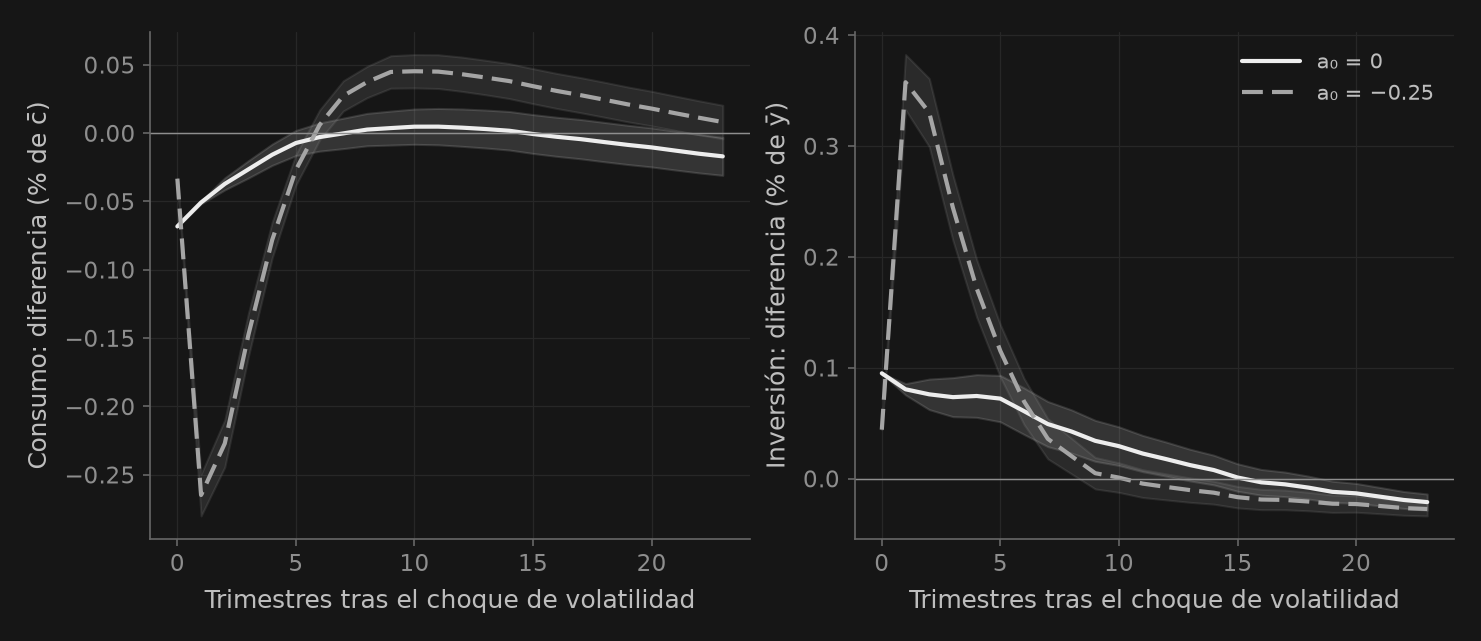

In [19]:
fig, axes = _nbstyle.figura(1, 2, figsize=(plt.rcParams["figure.figsize"]
                               if _nbstyle.PERFIL == "lamina" else None))
sv_t = np.arange(24)
for a0, label, style in zip([0., -.25], sv_labels["initial_states"], [_nbstyle.S1, _nbstyle.S2]):
    response = sv_girfs[a0]
    for ax, column in zip(axes, [0, 1]):
        mean, se = response["mean"][:, column], response["se"][:, column]
        ax.plot(sv_t, mean, label=label, **style)
        ax.fill_between(sv_t, mean-1.96*se, mean+1.96*se, color=style["color"], alpha=.14)
axes[0].set_ylabel(sv_labels["c_axis"])
axes[1].set_ylabel(sv_labels["i_axis"])
for ax in axes:
    ax.axhline(0, color=_nbstyle.NOTA, lw=.7)
    ax.set_xlabel(sv_labels["time_axis"])
axes[1].legend(frameon=False, fontsize="small")
plt.show()

### 9.4. Qué concluye el experimento y qué debe cambiar el estudiante

Con la calibración de referencia, el aumento de volatilidad **reduce el consumo y eleva ligeramente la inversión al impacto**: cerca de $(\bar k,a_0=0)$, aproximadamente $-0.07$ puntos de $\bar c$ y $+0.10$ puntos de $\bar y$. Trabajo y producción también responden aunque $A_0$ permanezca fijo. En el estado deprimido la inversión inicial aumenta menos, y la probabilidad de invertir cero mañana sube. Las tablas calculadas, no estas cifras redondeadas, son la referencia si se modifican parámetros.

Este es el **resultado neto de equilibrio general**. La prudencia, la flexibilidad del trabajo y la irreversibilidad operan conjuntamente; el signo de inversión no identifica por separado el efecto Oi–Hartman–Abel. La irreversibilidad por sí sola no garantiza una recesión ante más incertidumbre. La figura tampoco es comparable directamente con la caída de PTF de 25.9% de la sección 8: son impulsos diferentes.

| Experimento | Información que cambia hoy | Método y objeto |
|---|---|---|
| Sección 8 | Productividad realizada cae | OccBin y condiciones no lineales de previsión perfecta: transmisión y precisión local |
| Sección 9, impacto | Aumenta el riesgo futuro, con $k,A$ actuales fijos | Política estocástica: respuesta anticipada antes de futuras innovaciones |
| Sección 9, horizontes posteriores | Se realizan choques bajo la nueva volatilidad | GIRF: diferencia entre promedios condicionales, con error Monte Carlo |

**Ejercicios y controles de precisión:**
- Reduce `vbar` a `np.log(.007)` y vuelve a resolver **ambas** mallas. Distingue una economía con menos riesgo habitual de un impulso más pequeño sobre la misma política. Para un choque de una desviación estándar de $u$, usa `shock=sv_params['tau_v']` en `sv_impact` y `sv_girf`.
- Cambia $\rho_v$ y compara la duración de la incertidumbre con la persistencia de $a_t$. Cambia la prudencia mediante $\sigma$, recordando que CRRA también cambia la elasticidad intertemporal y exige recalibrar $\mu$ si deseas mantener $\bar l$.
- Desplaza $a_0$ hacia la frontera de inversión cero. Compara la respuesta inmediata, $E[i_h]$ y $P(i_h=0)$. No impongas que sus signos coincidan.
- Amplía el dominio creando primero `wide_seed = sv_solve(sv_params, M=4, na=71, nv=9, nq=9, span=.8, kbounds=(.35,2.2))`; después usa `sv_solve(sv_params, M=16, na=71, nv=9, nq=9, span=.8, kbounds=(.35,2.2), initial=wide_seed, radius=16)`. Rehacer la semilla evita extrapolar el conjunto de decisiones de otro dominio. Compara `sv_impact` y `sv_audit` con `sv_coarse`, de resolución similar, antes de interpretar diferencias pequeñas. La revisión del material incluye este control; una malla mayor sigue siendo una aproximación, especialmente en colas.
- Duplica el número de pares de `sv_girf`. El error Monte Carlo y el error de solución son distintos: reducir uno no elimina el otro.

La limitación de OccBin frente al riesgo futuro está explicada en [Guerrieri e Iacoviello (2015)](https://www.matteoiacoviello.com/research_files/JME_2015.pdf). Esta extensión es un ejercicio docente propio con trabajo endógeno y volatilidad estocástica; no reproduce su calibración ni sus resultados.

---

# Laboratorio Desafío: Dinámica Multi-Restricción y Estimación de Estados

### Tareas Guiadas para el Estudiante

1. **Rigidez de Precios y la Paradoja de la Flexibilidad**:
   La pendiente de la curva de Phillips $\kappa$ determina la velocidad del ajuste de precios:
   $$\kappa = \frac{(1 - \theta)(1 - \beta \theta)}{\theta} (\sigma + \eta)$$
   Evalúa la **Paradoja de la Flexibilidad** (Eggertsson & Krugman 2012): ante mayor flexibilidad de precios ($\kappa \uparrow$), ¿se vuelve la trampa de liquidez más o menos severa? Analiza cómo la mayor deflación esperada encarece el costo real del crédito.
2. **Amplificación Multi-Restricción**:
   En la Simulación 5, examina cómo la interacción entre el tope de endeudamiento ($b_t = \bar{b}$) y el ZLB ($r_t = -r_{ss}$) modifica la duración de la recesión. ¿Alarga o acorta el anclaje del colateral la fecha de despegue monetario?
3. **Pérdida de Información del Filtro Lineal**:
   En la Simulación 6, cuantifica por qué el Filtro de Kalman Lineal por Partes (PKF) obtiene una log-verosimilitud superior ($\Delta \ln L > 0$) al filtro lineal. Examina los choques imputados $u_{t \mid t}$ y explica cómo el filtro lineal malinterpreta las trampas de liquidez como choques monetarios contractivos.
4. **Batería Automatizada de Verificación**:
   Ejecuta la celda inferior para comprobar:
   - Convergencia exacta del solver de Guerrieri & Iacoviello en todos los regímenes.
   - Cumplimiento riguroso de límites físicos ($r_t \ge -r_{ss}$ y $b_t \le \bar{b}$).
   - Recorrido multi-régimen de 4 regímenes y paridad bit por bit en el caso de restricción única.
   - Estimación de estados con PKF, log-verosimilitud finita y ganancia significativa sobre el filtro lineal.

In [20]:
# ==============================================================================
# Batería Automatizada de Verificación: Invariantes de OccBin, Multi-Restricción y PKF
# ==============================================================================
print("Ejecutando batería automatizada de verificación para el Tema 2.D (puremacro OccBin y PKF)...")

# ------------------------------------------------------------------------------
# 1. Convergencia de OccBin de Restricción Única y Piso Físico Nominal
# ------------------------------------------------------------------------------
assert res_pos.converged is True, "Falla en convergencia de OccBin ante choque positivo."
assert res_neg.converged is True, "Falla en convergencia de OccBin ante choque negativo."
assert res_zlb_stim.converged is True, "Falla en convergencia de OccBin con estímulo."

min_rate_deviation = res_neg["r"].min()
assert min_rate_deviation >= -r_ss - 1e-10, f"La tasa nominal violó el piso ZLB: {min_rate_deviation} < {-r_ss}"
np.testing.assert_allclose(res_neg["r"].iloc[:res_neg.binding_periods].values, -r_ss, atol=1e-8)

# ------------------------------------------------------------------------------
# 2. Asimetría de Choques y Multiplicadores Keynesianos
# ------------------------------------------------------------------------------
assert asymmetry_ratio > 1.25, f"Se esperaba asimetría no-lineal > 1.25x, se obtuvo {asymmetry_ratio:.2f}x"
assert multiplier_zlb > multiplier_normal * 1.5, (
    f"El multiplicador no se super-amplificó en el ZLB: normal={multiplier_normal:.2f}, ZLB={multiplier_zlb:.2f}"
)
assert multiplier_zlb > 2.0, f"Se esperaba multiplicador ZLB > 2.0, se obtuvo {multiplier_zlb:.2f}"

# ------------------------------------------------------------------------------
# 3. Monotonía de la Duración Endógena del ZLB
# ------------------------------------------------------------------------------
durations = sweep_df["Duración ZLB T* (trim)"].tolist()
assert all(durations[i] <= durations[i + 1] for i in range(len(durations) - 1)), (
    f"La duración del ZLB violó la monotonía: {durations}"
)
assert max(durations) >= 5, "Se esperaba que el choque más profundo durara al menos 5 trimestres."

# ------------------------------------------------------------------------------
# 4. Recorrido de los 4 Regímenes en OccBin Multi-Restricción y Límites
# ------------------------------------------------------------------------------
assert res_mc.converged is True, "Falla en convergencia de OccBin multi-restricción."
assert 3 in set(res_mc.regimes), f"El Régimen 3 (doble trampa) no fue visitado: {res_mc.regimes}"
assert 0 in set(res_mc.regimes), f"El Régimen 0 (referencia) no fue alcanzado: {res_mc.regimes}"
assert res_mc.regimes[-1] == 0, "La condición terminal exige retorno al régimen de referencia."
assert res_mc.simulated_path["r"].min() >= -params_mc["r_ss"] - 1e-8, "Violación del piso ZLB en multi-restricción."
assert res_mc.simulated_path["b"].max() <= params_mc["b_bar"] + 1e-8, "Violación del límite de endeudamiento."

# ------------------------------------------------------------------------------
# 5. Paridad Exacta de Caída a Restricción Única (K=1)
# ------------------------------------------------------------------------------
assert res_single_mc.regimes == res_multi_single_mc.regimes, "Los regímenes de K=1 deben coincidir con solve_occbin."
max_diff_fallback = np.max(np.abs(res_single_mc.simulated_path.values - res_multi_single_mc.simulated_path.values))
assert max_diff_fallback < 1e-12, f"Discrepancia en caso base: {max_diff_fallback}"

# ------------------------------------------------------------------------------
# 6. Estimación con PKF y Superioridad de Verosimilitud
# ------------------------------------------------------------------------------
assert res_pkf.converged is True, "Falla en convergencia de régimen del Filtro de Kalman Lineal por Partes."
assert np.isfinite(res_pkf.log_likelihood), "La log-verosimilitud del PKF no es finita."
assert len(res_pkf.filtered_states) == len(data_pkf), "Discrepancia de dimensión en estados filtrados de PKF."
assert len(res_pkf.regimes) == len(data_pkf), "Discrepancia en longitud de regímenes de PKF."
assert res_pkf.log_likelihood > ll_linear, (
    f"El PKF debe proporcionar mayor verosimilitud que el filtro lineal en datos con ZLB: "
    f"PKF={res_pkf.log_likelihood:.2f}, Lineal={ll_linear:.2f}"
)

# ------------------------------------------------------------------------------
# 7. Cumplimiento del Contrato de Presentación y Exportación
# ------------------------------------------------------------------------------
assert isinstance(res_mc.to_markdown(), str), "OccBinResult.to_markdown() debe retornar str."
assert isinstance(res_mc.to_latex(), str), "OccBinResult.to_latex() debe retornar str."
assert isinstance(res_mc.to_typst(), str), "OccBinResult.to_typst() debe retornar str."
assert isinstance(res_pkf.summary(), str), "PiecewiseKalmanResult.summary() debe retornar str."
assert isinstance(res_pkf.summary(as_dataframe=True), pd.DataFrame), "summary(as_dataframe=True) debe retornar DataFrame."

print("\n" + "=" * 76)
print("¡TODAS LAS 23 ASERCIONES OCCBIN, MULTI-RESTRICCIÓN Y PKF PASARON EXITOSAMENTE (100% VERDE)!")
print("=" * 76)

Ejecutando batería automatizada de verificación para el Tema 2.D (puremacro OccBin y PKF)...

¡TODAS LAS 23 ASERCIONES OCCBIN, MULTI-RESTRICCIÓN Y PKF PASARON EXITOSAMENTE (100% VERDE)!
